# Imports

In [86]:
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import pandas as pd 
import polars as pl
import scipy.sparse as sp
import plotly.graph_objects as go
import plotly.express as px
import connexplorer as cnx
cnx.config.data_dir = "/Users/shayanafshar/Code/codexplorer/data"
ds = cnx.open('flywire')
pl.Config.set_fmt_str_lengths(100)

polars.config.Config

# Column Table

In [2]:
# Get root id and types for each 
marker_types = ['R7', 'R8', 'Mi1', 'L1', 'L2', 'L3', 'L5']
side = 'R'
columns_df = (ds.columns.filter(pl.col('side') == side).join(
    ds.cells.select(pl.col('id'), pl.col('root_id'), pl.col('type')),
    on='id')
    .filter(pl.col('type').is_in(marker_types))
    .group_by(pl.col('column_id')).agg(
        pl.col('p').first(), pl.col('q').first(),
        pl.col('root_id').filter(pl.col('type') == 'R7').first().alias('R7'),
        pl.col('root_id').filter(pl.col('type') == 'R8').first().alias('R8'),
        pl.col('root_id').filter(pl.col('type') == 'Mi1').first().alias('Mi1'),
        pl.col('root_id').filter(pl.col('type') == 'L1').first().alias('L1'),
        pl.col('root_id').filter(pl.col('type') == 'L2').first().alias('L2'),
        pl.col('root_id').filter(pl.col('type') == 'L3').first().alias('L3'),
        pl.col('root_id').filter(pl.col('type') == 'L5').first().alias('L5'),
        pl.col('root_id').filter(pl.col('type') == 'R7').len().alias('n_R7'),
        pl.col('root_id').filter(pl.col('type') == 'R8').len().alias('n_R8'),
        pl.col('root_id').filter(pl.col('type') == 'Mi1').len().alias('n_Mi1'),
        pl.col('root_id').filter(pl.col('type') == 'L1').len().alias('n_L1'),
        pl.col('root_id').filter(pl.col('type') == 'L2').len().alias('n_L2'),
        pl.col('root_id').filter(pl.col('type') == 'L3').len().alias('n_L3'),
        pl.col('root_id').filter(pl.col('type') == 'L5').len().alias('n_L5'),
        pl.col('type').is_in(['R7', 'R8']).any().alias('has_PR'))
)

# Sanity checks 
print(f'# of expected columns in right OL: 796, # of found columns: {columns_df.select('column_id').n_unique()}')
print(f'# of columns with an R7: {columns_df.filter(pl.col('n_R7') > 0).select('column_id').n_unique()}')
print(f'# of columns with an R8: {columns_df.filter(pl.col('n_R8') > 0).select('column_id').n_unique()}')
print(f'# of columns with both: {columns_df.filter(pl.col('n_R8')*pl.col('n_R7') > 0).select('column_id').n_unique()}')
print(f'# of columns with more than 1 R7: {columns_df.filter(pl.col('n_R7') > 1).select('column_id').n_unique()}')
print(f'# of columns with more than 1 R8: {columns_df.filter(pl.col('n_R8') > 1).select('column_id').n_unique()}')
print(f'# of edge columns: {columns_df.filter(pl.col('has_PR').not_()).select('column_id').n_unique()}')

# of expected columns in right OL: 796, # of found columns: 796
# of columns with an R7: 659
# of columns with an R8: 654
# of columns with both: 632
# of columns with more than 1 R7: 0
# of columns with more than 1 R8: 0
# of edge columns: 115


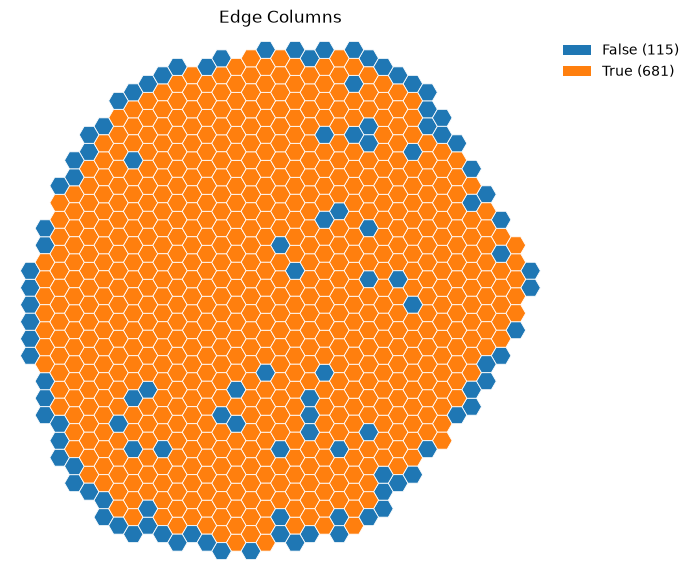

In [3]:
cnx.viz.hexmap(columns_df, 'has_PR')
plt.title('Edge Columns');

# Column axis / depth in the medulla

In [4]:
grp = ds.select(pl.col('type').is_in(marker_types) & (pl.col('side') == side))
syns = grp.synapses(direction='both')
print(f"shape: {syns.shape} and neuropils: {syns.select('neuropil').unique()}")

# Filtering 
syns = syns.filter(pl.col('neuropil') == 'ME_R')
syns = syns.with_columns(
    (pl.col('x_nm') / 1000).alias('x'),
    (pl.col('y_nm') / 1000).alias('y'),
    (pl.col('z_nm') / 1000).alias('z')
).select(pl.all().exclude('x_nm', 'y_nm', 'z_nm'))
print(f"shape: {syns.shape} and neuropils: {syns.select('neuropil').unique()}")

shape: (4170057, 6) and neuropils: shape: (5, 1)
┌──────────┐
│ neuropil │
│ ---      │
│ str      │
╞══════════╡
│ AME_R    │
│ ME_R     │
│ LH_R     │
│ LA_R     │
│ null     │
└──────────┘
shape: (3497007, 6) and neuropils: shape: (1, 1)
┌──────────┐
│ neuropil │
│ ---      │
│ str      │
╞══════════╡
│ ME_R     │
└──────────┘


In [5]:
# Marker ids 
ids = columns_df.unpivot(index=['column_id'], on=marker_types, variable_name='type', value_name='root_id').drop_nulls()
# Joining with the synapse table 
pre_df = syns.join(ids, left_on='pre', right_on='root_id').with_columns(pl.lit('pre').alias('role'))
post_df = syns.join(ids, left_on='post', right_on='root_id').with_columns(pl.lit('post').alias('role'))
marker_df = pl.concat([pre_df, post_df])
# Sanity checks
print(f'# of expected columns in right OL: 796, # of found columns: {marker_df.select('column_id').n_unique()}')
print(f'Number of roles for an R7: {marker_df.filter(pl.col('type') == 'R7').select('role').n_unique()}')
marker_df.group_by("type", "role").len().sort("type", "role").show(-1)

# of expected columns in right OL: 796, # of found columns: 796
Number of roles for an R7: 2


type,role,len
str,str,u32
"""L1""","""post""",88822
"""L1""","""pre""",365176
"""L2""","""post""",149716
"""L2""","""pre""",622259
"""L3""","""post""",50337
"""L3""","""pre""",270775
"""L5""","""post""",249699
"""L5""","""pre""",455196
"""Mi1""","""post""",343619


In [6]:
# Finding the straight axis per column
column_markers = marker_df.partition_by('column_id', as_dict=True)
column_axes = []
for column, df in column_markers.items():

    # Point cloud spread 
    points = df.select('x', 'y', 'z').to_numpy()
    centroid = points.mean(axis=0)
    _, _, vt = np.linalg.svd(points - centroid, full_matrices=False)

    # Depth axis
    u = vt[0]

    # Projections 
    t = (points - centroid) @ u
    t_min = t.min()
    t_max = t.max()
    t_1 = np.percentile(t, 1)
    t_99 = np.percentile(t, 99)

    rule = 'mi1_l1'
    deep_mask = df.select((pl.col('type') == 'Mi1') & (pl.col('role') == 'pre')).to_numpy().squeeze()
    shallow_mask = df.select((pl.col('type') == 'L1') & (pl.col('role') == 'pre')).to_numpy().squeeze()
    if (deep_mask.sum() < 20) or (shallow_mask.sum() < 20): # Threshold 
        deep_mask = df.select((pl.col('type') == 'R7') & (pl.col('role') == 'pre')).to_numpy().squeeze()
        shallow_mask = df.select((pl.col('type') == 'R8') & (pl.col('role') == 'pre')).to_numpy().squeeze()
        rule = 'r7_r8'
    if deep_mask.sum() < 20 or shallow_mask.sum() < 20:
        depth_dir = np.full(u.shape, np.nan)
        rule = 'none'
    else:
        depth_dir = points[deep_mask].mean(axis=0) - points[shallow_mask].mean(axis=0)

    sign = np.nan if np.isnan(depth_dir).any() else (1.0 if depth_dir @ u >= 0 else -1.0)


    # Storing output 
    results = {'column_id': column[0], 
               'cx': centroid[0], 'cy': centroid[1], 'cz': centroid[2],
               'ux': u[0], 'uy': u[1], 'uz': u[2],
               't_min': t_min, 't_max': t_max, 't_1': t_1, 't_99': t_99,
               'sign': sign,
               'rule': rule}
    column_axes.append(results)

axes_df = pl.DataFrame(column_axes)
axes_df = (axes_df.with_columns(pl.when(pl.col('sign').is_nan())
                                .then(pl.lit('none'))
                                .otherwise(pl.lit('landmark'))
                                .alias('oriented'))
           )
axes_df = axes_df.join(columns_df.select('column_id', 'p', 'q'), on='column_id')
print(f'missing_columns: {axes_df.filter(pl.col('oriented') == 'none').select('column_id')}' )

missing_columns: shape: (3, 1)
┌───────────┐
│ column_id │
│ ---       │
│ i64       │
╞═══════════╡
│ 516       │
│ 782       │
│ 62        │
└───────────┘


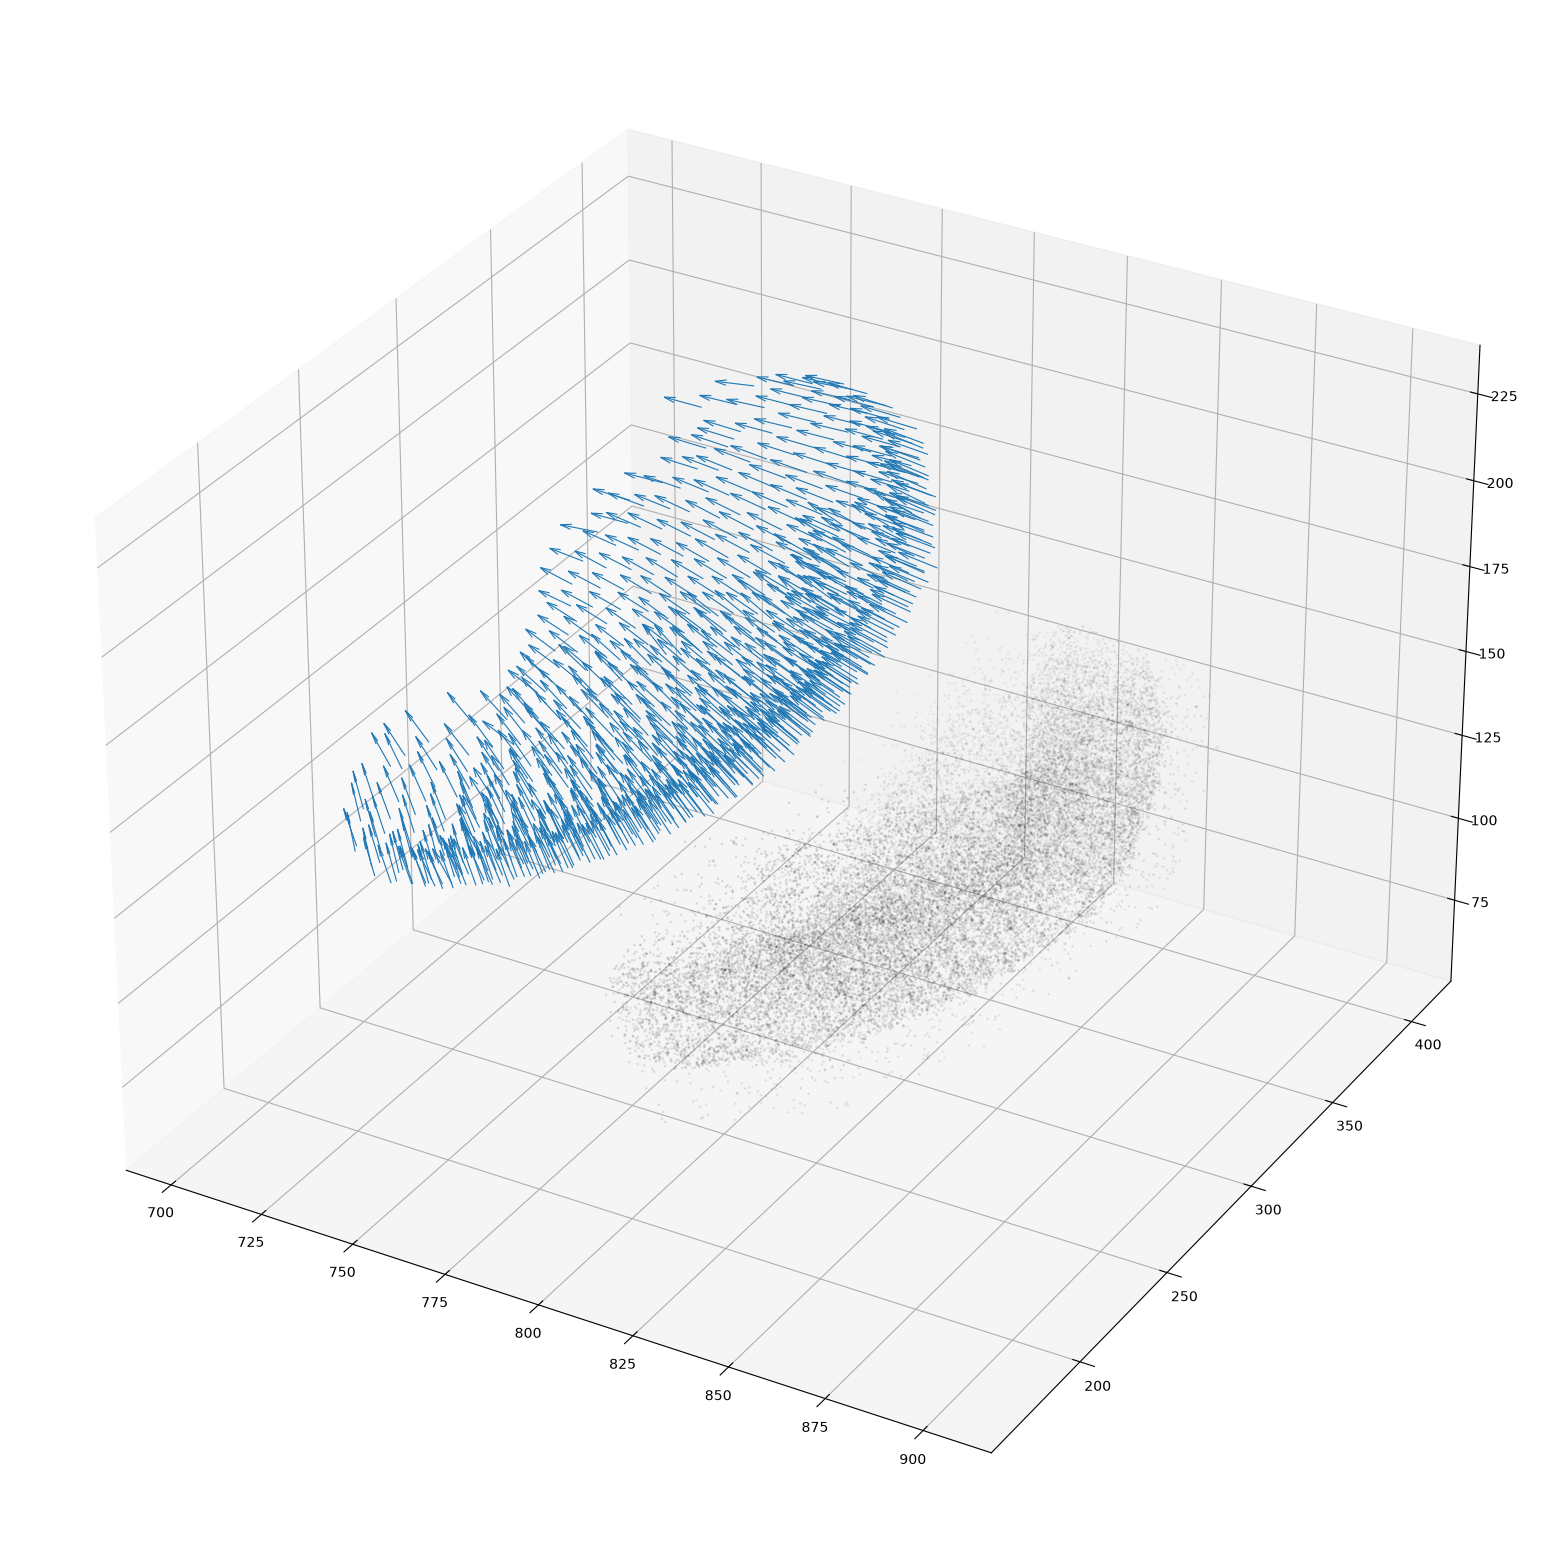

In [7]:
fig = plt.figure(figsize=(20, 20))
ax = fig.add_subplot(projection="3d")
ax.quiver(axes_df["cx"], axes_df["cy"], axes_df["cz"], 
          axes_df["ux"]*axes_df['sign'], axes_df["uy"]*axes_df['sign'], axes_df["uz"]*axes_df['sign'], 
          length=10, normalize=True, linewidth=0.8)
la = ds.synapses.scan().filter(pl.col("neuropil") == "LA_R").collect().sample(25000, seed=0)
ax.scatter(la["x_nm"] / 1000, la["y_nm"] / 1000, la["z_nm"] / 1000, s=1, c="k", alpha=0.3);


In [8]:
# Fixing missing depth vectors 
rows = {r["column_id"]: r for r in axes_df.iter_rows(named=True)}
by_pq = {(r["p"], r["q"]): cid for cid, r in rows.items()}
u0 = {cid: np.array([r["ux"], r["uy"], r["uz"]]) for cid, r in rows.items()}
sign = {cid: r["sign"] for cid, r in rows.items()}
rules = {cid: r['rule'] for cid, r in rows.items()}
oriented = {cid: r["oriented"] for cid, r in rows.items()}

changed = True 
while changed:
    changed = False
    for cid, r in rows.items():
        # Skip already assigned orientations
        if oriented[cid] != 'none':
            continue
        # Grab neighbors of unassigned sites
        nb = [by_pq[site] for site in cnx.viz.hex_neighbors(r['p'], r['q']) if site in by_pq and oriented[by_pq[site]] != 'none']
        # Skip this site if it has no neighbors (rim columns + missing depths)
        if not nb: continue
        # Assign mean sign for missing columns
        ref = np.mean([sign[site] * u0[site] for site in nb], axis=0)
        sign[cid] = 1.0 if u0[cid] @ ref >= 0.0 else -1.0
        oriented[cid] = 'neighbors'
        rules[cid] = 'neighbors'
        changed=True

print("still unoriented:", [c for c, s in oriented.items() if s == "none"])

# Write new orientations back in 
axes_df = axes_df.with_columns(
    pl.col('column_id').replace_strict(sign).alias('sign'),
    pl.col('column_id').replace_strict(oriented).alias('oriented'),
    pl.col('column_id').replace_strict(rules).alias('rule')
)

still unoriented: []


Potential disagreements: 0


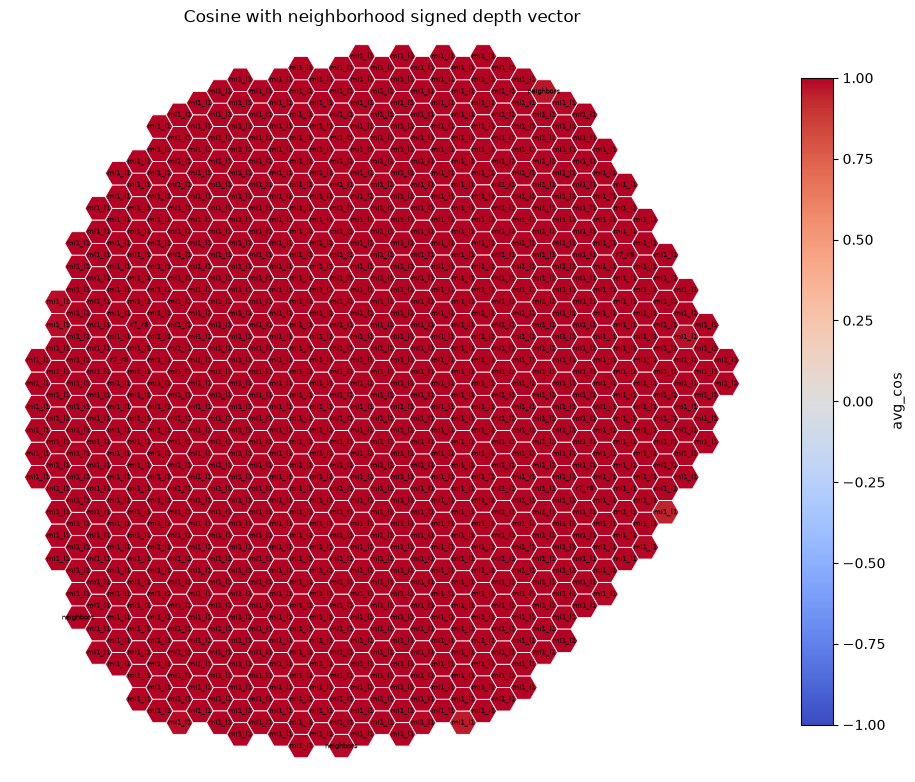

In [9]:
# Looking at agreements in neighborhoods of  depth vectors 
nb_test = {cid: np.nan for cid in rows.keys()}
for cid, r in rows.items():
    # Get neighbors 
    nb = [by_pq[site] for site in cnx.viz.hex_neighbors(r['p'], r['q']) if site in by_pq]
    # Skip if there are no neighbors 
    if not nb: continue 
    # Find mean orientation 
    ref = np.mean([sign[site] * u0[site] for site in nb], axis=0)
    alignment = ref @ (u0[cid] * sign[cid])
    nb_test[cid] = alignment / np.linalg.norm(ref)

print(f'Potential disagreements: {(np.array(list(nb_test.values())) < 0).sum()}')

# Looking at the differences 
align_df = axes_df.select('column_id', 'p', 'q', 'rule').with_columns(
    pl.col('column_id').replace_strict(nb_test).alias('avg_cos')
)
fig, ax = plt.subplots(figsize=(12,12))
cnx.viz.hexmap(align_df, values='avg_cos', annotate='rule', cmap='coolwarm', vmax=1.0, vmin=-1.0, ax=ax)
plt.title('Cosine with neighborhood signed depth vector');

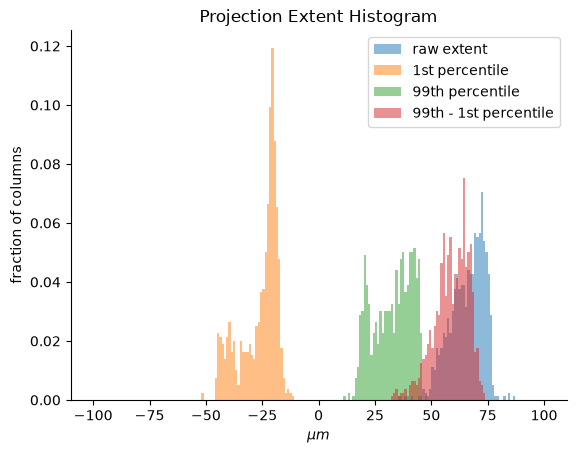

In [10]:
# Projection distribution 
t_range = np.abs((axes_df.select('t_max') - axes_df.select('t_min'))).squeeze()
t_1 = axes_df.select('t_1')
t_99 = axes_df.select('t_99')
plt.hist(t_range, bins=np.linspace(-100, 100, 201), density=True, alpha=0.5, label='raw extent');
plt.hist(t_1, bins=np.linspace(-100, 100, 201), density=True, alpha=0.5, label='1st percentile');
plt.hist(t_99, bins=np.linspace(-100, 100, 201), density=True, alpha=0.5, label='99th percentile');
plt.hist(t_99 - t_1, bins=np.linspace(-100, 100, 201), density=True, alpha=0.5, label='99th - 1st percentile')
plt.xlabel(r'$\mu m$');
plt.ylabel('fraction of columns')
plt.title('Projection Extent Histogram')
sns.despine()
plt.legend();

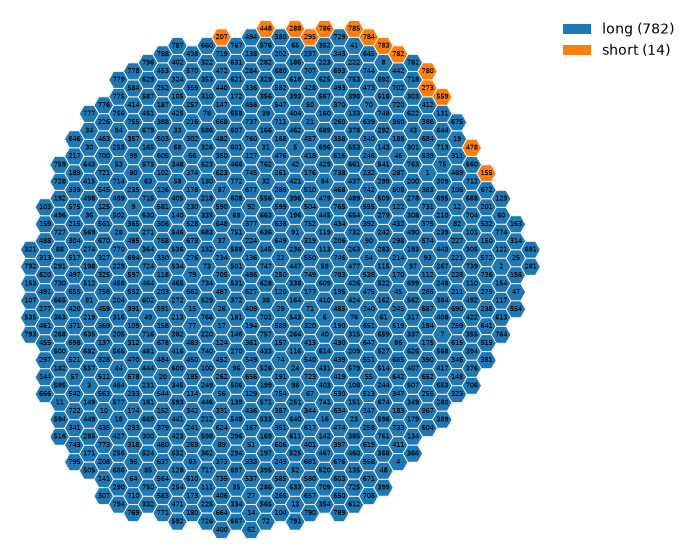

In [11]:
view = axes_df.with_columns(
    pl.when(pl.col('t_99') - pl.col('t_1') < 40).then(pl.lit('short')).otherwise(pl.lit('long')).alias('outlier')
)
cnx.viz.hexmap(view, values='outlier', annotate=True);

In [12]:
# Adding oriented depth axes to the axes_df 
oriented_df = axes_df.with_columns(
    (pl.col('ux') * pl.col('sign')).alias('ux'),
    (pl.col('uy') * pl.col('sign')).alias('uy'),
    (pl.col('uz') * pl.col('sign')).alias('uz'),
    (pl.min_horizontal(pl.col('t_max') * pl.col('sign'), pl.col('t_min') * pl.col('sign'))).alias('t_min'),
    (pl.max_horizontal(pl.col('t_max') * pl.col('sign'), pl.col('t_min') * pl.col('sign'))).alias('t_max'),
    (pl.min_horizontal(pl.col('t_1') * pl.col('sign'), pl.col('t_99') * pl.col('sign'))).alias('t_1'),
    (pl.max_horizontal(pl.col('t_1') * pl.col('sign'), pl.col('t_99') * pl.col('sign'))).alias('t_99'),
).select(pl.all().exclude('sign'))

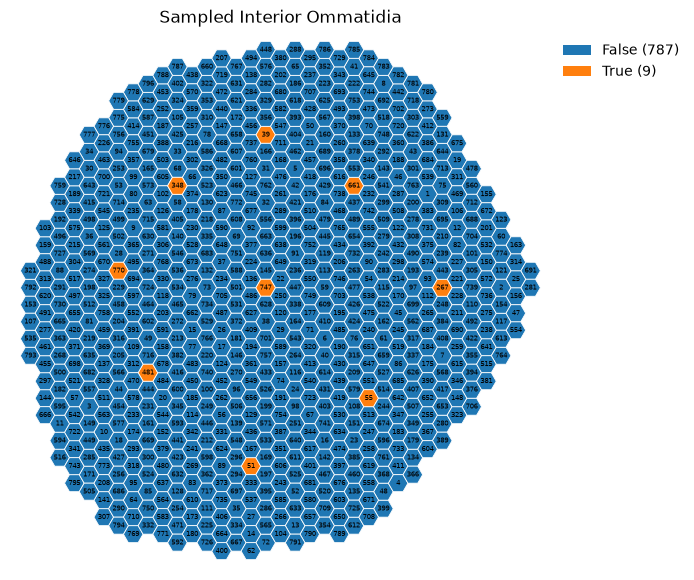

In [13]:
interior_columns = [39, 770, 51, 267, 747, 661, 55, 481, 348] # All columns have > 20 of each marker type
a = columns_df.with_columns(pl.col('column_id').is_in(interior_columns).alias('sampled'))
cnx.viz.hexmap(a, values='sampled', annotate=True)
plt.title('Sampled Interior Ommatidia');

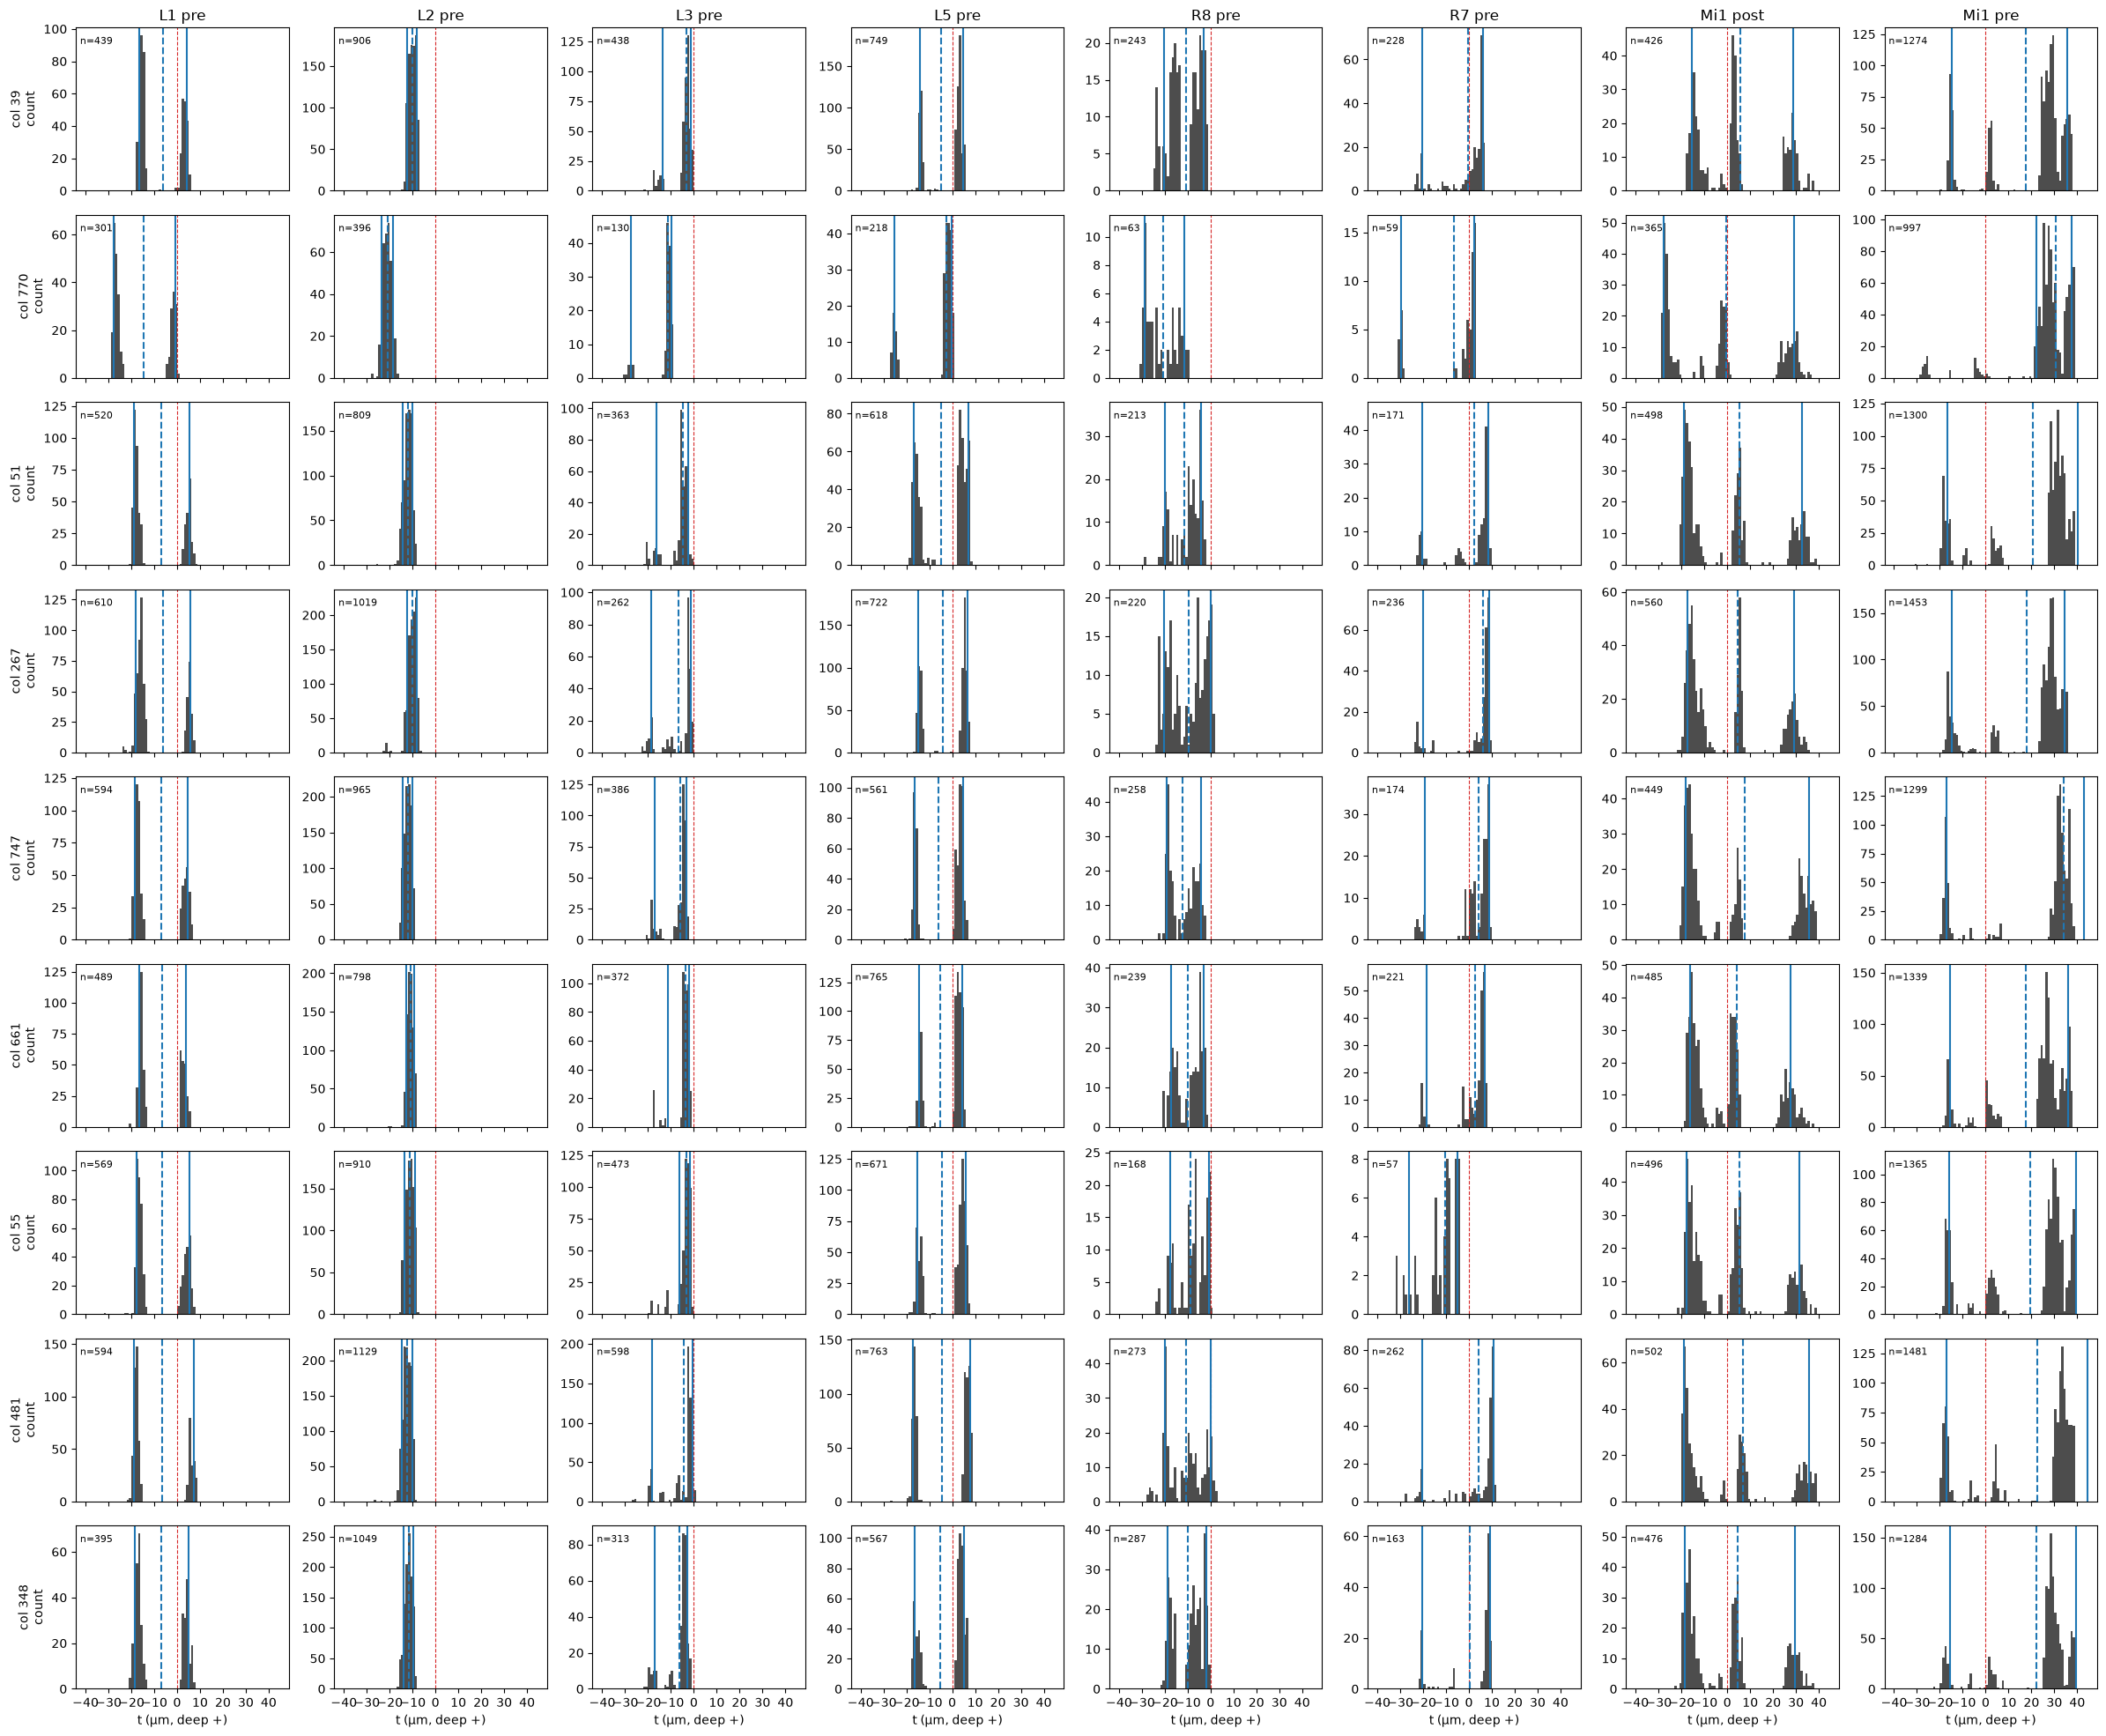

In [14]:
depth_df = marker_df.join(oriented_df, on='column_id')
depth_df = depth_df.with_columns(
    ((pl.col('x') - pl.col('cx'))*pl.col('ux') + 
     (pl.col('y') - pl.col('cy'))*pl.col('uy') + 
     (pl.col('z') - pl.col('cz'))*pl.col('uz')).alias('t')
)

landmarks = [("L1", "pre"), ("L2", "pre"), ("L3", "pre"), ("L5", "pre"), ("R8", "pre"), ("R7", "pre"), ("Mi1", "post"), ("Mi1", "pre")]
bins = np.arange(-40, 40, 1.0)

fig, axs = plt.subplots(len(interior_columns), len(landmarks),
                        figsize=(3 * len(landmarks), 2.2 * len(interior_columns)),
                        sharex=True, layout="tight")

for i, cid in enumerate(interior_columns):
    col_df = depth_df.filter(pl.col("column_id") == cid)
    for j, (typ, role) in enumerate(landmarks):
        ax = axs[i, j]
        t = col_df.filter((pl.col("type") == typ) & (pl.col("role") == role))["t"].to_numpy()
        ax.hist(t, bins=bins, color="0.3")
        # centroid position
        ax.axvline(0, color="tab:red", lw=0.8, ls="--")
        # Percentiles for individual band approximations
        ax.axvline(np.percentile(t, 10), color='tab:blue')
        ax.axvline(np.percentile(t, 90), color='tab:blue')
        ax.axvline((np.percentile(t, 80) + np.percentile(t, 20)) / 2, color='tab:blue', ls="--")             
        if i == 0:
            ax.set_title(f"{typ} {role}")
        if j == 0:
            ax.set_ylabel(f"col {cid}\ncount")
        if i == len(interior_columns) - 1:
            ax.set_xlabel("t (µm, deep +)")
            ax.set_xticks(np.arange(-40, 50, 10))
        ax.text(0.02, 0.9, f"n={len(t)}", transform=ax.transAxes, fontsize=8)

# Across layer spans are consistent for a given cell type (e.g. L1 has 2 main arbor locations) across sampled columns

L5 band is -0.09 um deeper than L1 (n=745); after correction |L5 - L1| median 0.25, max 1.87 um
shape: (3, 2)
┌───────────┬───────┐
│ t0_source ┆ count │
│ ---       ┆ ---   │
│ str       ┆ u32   │
╞═══════════╪═══════╡
│ L1        ┆ 781   │
│ none      ┆ 6     │
│ L5        ┆ 9     │
└───────────┴───────┘


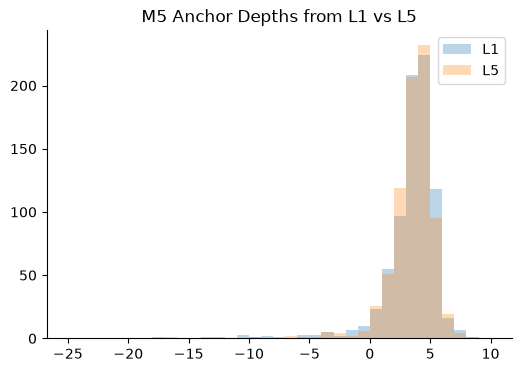

In [15]:
anchor_struct = pl.Struct({'t0': pl.Float64, 'sep': pl.Float64, 'n_deep': pl.Float64, 'n_shallow': pl.Float64})

def get_m5_anchors(t):
    """Use the 20th and 80th percentile to get the M1 and M5 bands. Return the M5 anchor and 
    other info necessary to judge the split."""
    t = np.sort(np.asarray(t, dtype=float))
    t_split = np.mean([np.percentile(t, 20), np.percentile(t,80)])
    shallow, deep = t[t <= t_split], t[t > t_split]
    return {
        't0': float(np.median(deep)) if len(deep) else float('nan'),
        'sep': float(np.median(deep) - np.median(shallow)) if len(deep) and len(shallow) else float('nan'),
        'n_deep': float(len(deep)),
        'n_shallow': float(len(shallow))
    }

def anchors_for(depth_df, cell_type, min_n=20):
    "M5 anchor per column from one lamina cell type's output depths (L1 or L5)"
    anchor_df = (
        depth_df.filter((pl.col('type') == cell_type) & (pl.col('role') == 'pre'))
        .group_by('column_id').agg(pl.col('t'), pl.len().alias('n'))
        .filter(pl.col('n') >= min_n)
        .with_columns(pl.col('t').map_elements(get_m5_anchors, return_dtype=anchor_struct).alias('a'))
        .unnest('a')
        .with_columns((pl.col('sep').is_between(10, 30)  & (pl.col('n_deep') >= min_n) & (pl.col('n_shallow') >= min_n)).alias('anchor_ok'))
        .select('column_id', 't0', 'sep', 'n_deep', 'n_shallow', 'anchor_ok', 'n')
    ) 
    return anchor_df

l1_anchors = anchors_for(depth_df, 'L1')
l5_anchors = anchors_for(depth_df, 'L5')

# Produce an L1 vs L5 m5 depth histogram comparison 
fig, ax = plt.subplots(figsize=(6,4))
ax.hist(l1_anchors['t0'], bins=np.linspace(-25, 10, 36), label='L1', alpha=0.3)
ax.hist(l5_anchors['t0'], bins=np.linspace(-25, 10, 36), label='L5', alpha=0.3)
ax.set_title('M5 Anchor Depths from L1 vs L5')
ax.legend()
sns.despine();

# the L5 M5 band sits a little deeper than L1's: measure that once where both are valid
both = (l1_anchors.filter(pl.col("anchor_ok")).select("column_id", pl.col("t0").alias("t0_l1"))
        .join(l5_anchors.filter(pl.col("anchor_ok")).select("column_id", pl.col("t0").alias("t0_l5")), on="column_id"))
l5_offset = float((both["t0_l5"] - both["t0_l1"]).median())
resid = both["t0_l5"] - l5_offset - both["t0_l1"]
print(f"L5 band is {l5_offset:.2f} um deeper than L1 (n={both.height}); "
      f"after correction |L5 - L1| median {resid.abs().median():.2f}, max {resid.abs().max():.2f} um")

# Aggregating the L5 and L1 anchors 
ref = (
    columns_df.select('column_id', 'p', 'q')
    .join(l1_anchors.filter(pl.col('anchor_ok')).select(
        'column_id', pl.col('t0').alias('t0_l1'), pl.col('sep').alias('sep_l1'), pl.col('n_deep').alias('n_deep_l1'), pl.col('n_shallow').alias('n_shallow_l1')
        ), on='column_id', how='left')
    .join(l5_anchors.filter(pl.col('anchor_ok')).select(
        'column_id', (pl.col('t0') - l5_offset).alias('t0_l5'), pl.col('sep').alias('sep_l5'), pl.col('n_deep').alias('n_deep_l5'), pl.col('n_shallow').alias('n_shallow_l5')
        ), on='column_id', how='left')
    .with_columns(
        pl.coalesce('t0_l1', 't0_l5').alias('t0'),
        pl.coalesce('sep_l1', 'sep_l5').alias('sep'),
        pl.coalesce('n_deep_l1', 'n_deep_l5').alias('n_deep'),
        pl.coalesce('n_shallow_l1', 'n_shallow_l5').alias('n_shallow'),
        pl.when(pl.col('t0_l1').is_not_null()).then(pl.lit('L1'))
        .when(pl.col('t0_l5').is_not_null()).then(pl.lit('L5'))
        .otherwise(pl.lit('none')).alias('t0_source')
    )
    .select('column_id', 'p', 'q', 't0', 't0_source', 'sep', 'n_deep', 'n_shallow')
)

# Inspecting columns where synapses are not available
print(ref['t0_source'].value_counts())

2


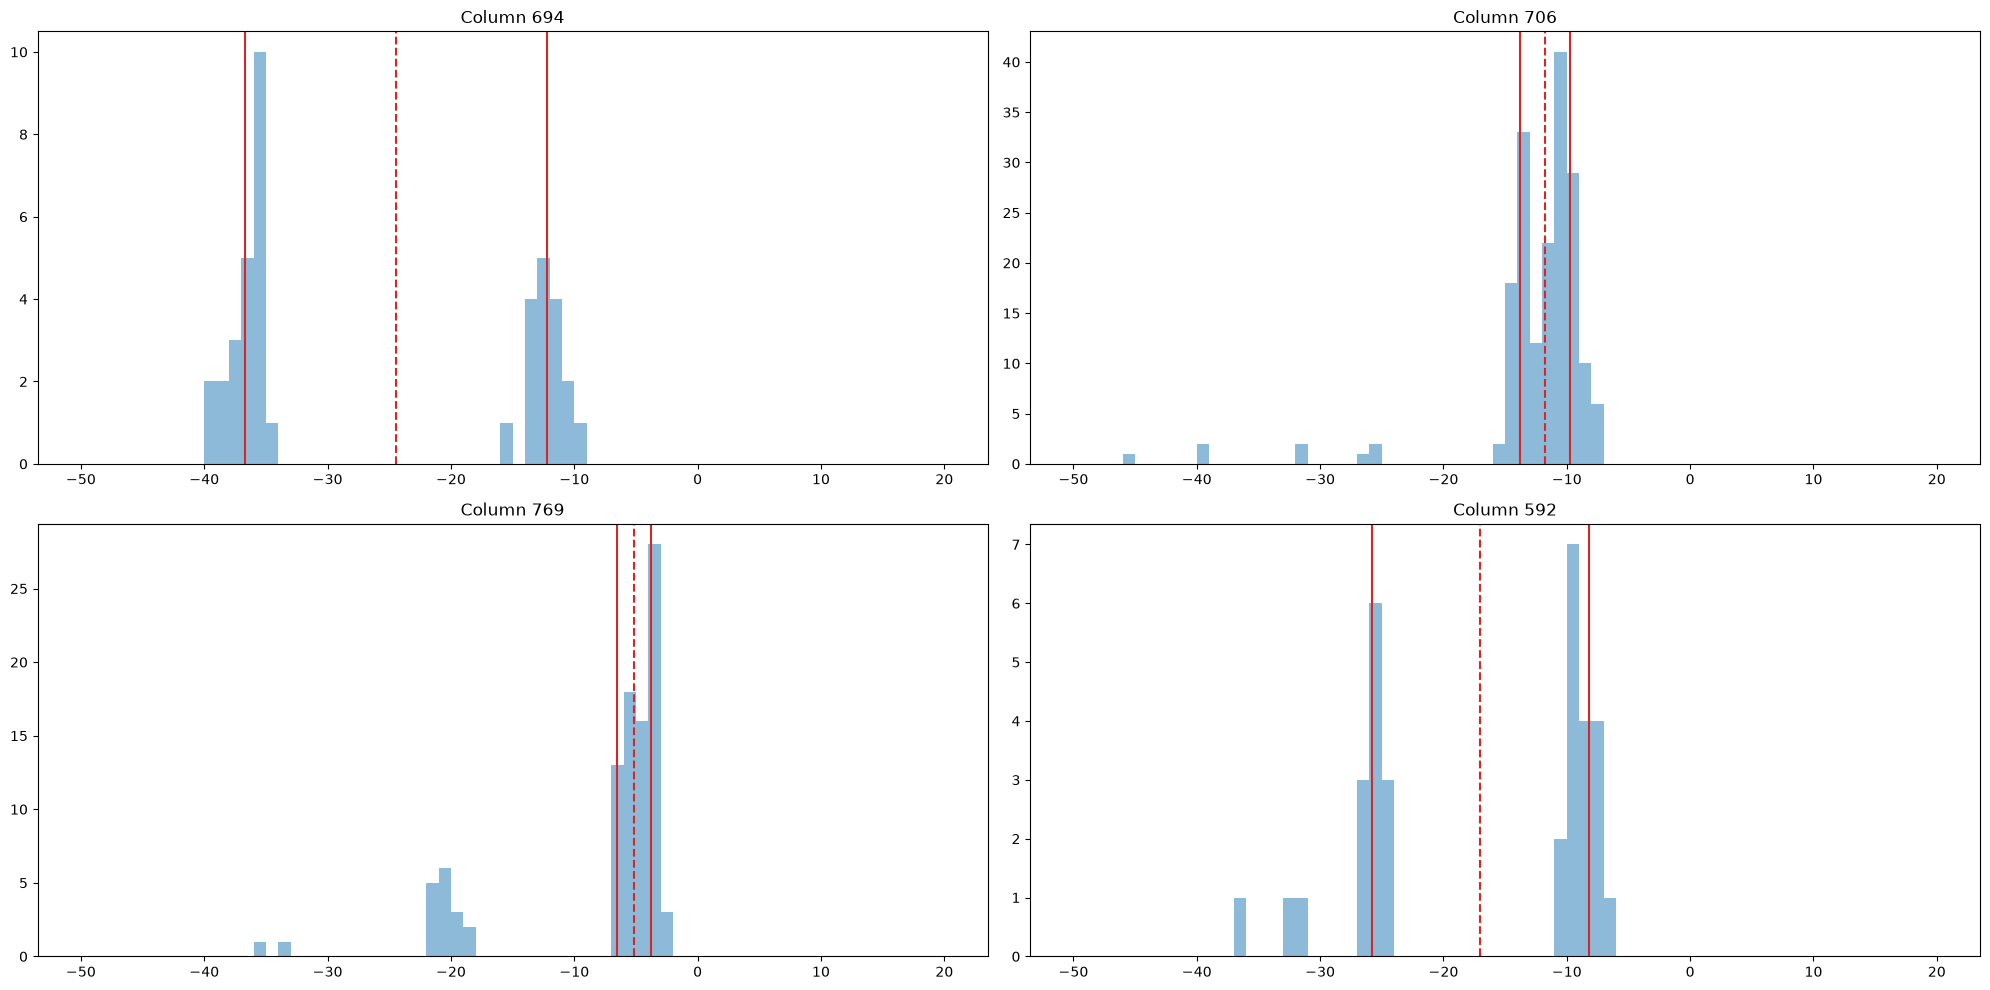

In [16]:
# Sampling a couple of bad columns and looking at L1 and L5 histograms
bad_columns = ref.filter(pl.col('t0_source') == 'none')['column_id'].to_numpy().squeeze()

def view_bad_cols(df, cols, cell_type='L1'):
    view = (df.filter(
        (pl.col('type') == cell_type) & (pl.col('role') == 'pre') & (pl.col('column_id').is_in(cols)))
        .group_by('column_id').agg(pl.col('t'), pl.len().alias(f'n_{cell_type}'))
    )
    fig_dim = int(np.ceil(np.sqrt(len(view))))
    print(fig_dim)
    fig, axs = plt.subplots(fig_dim, fig_dim, figsize=(20,10), sharex=False, layout='tight')
    for i in range(len(view)):
        if fig_dim == 1:
            ax = axs
        else:
            ax = axs.flat[i]
        t = view[i, 't'].to_numpy().squeeze()
        ax.hist(t, bins=np.linspace(-50, 20, 71), alpha=0.5)
        ax.set_title(f'Column {view[i].select('column_id').to_numpy().squeeze()}')
        ax.axvline(np.percentile(t, 20), color='tab:red')
        ax.axvline(np.percentile(t, 80), color='tab:red')
        ax.axvline((np.percentile(t, 80) + np.percentile(t, 20)) / 2, color='tab:red', ls="--")   

view_bad_cols(depth_df, bad_columns, 'L1')
#plt.savefig('bad_columns_L5.png', bbox_inches='tight')

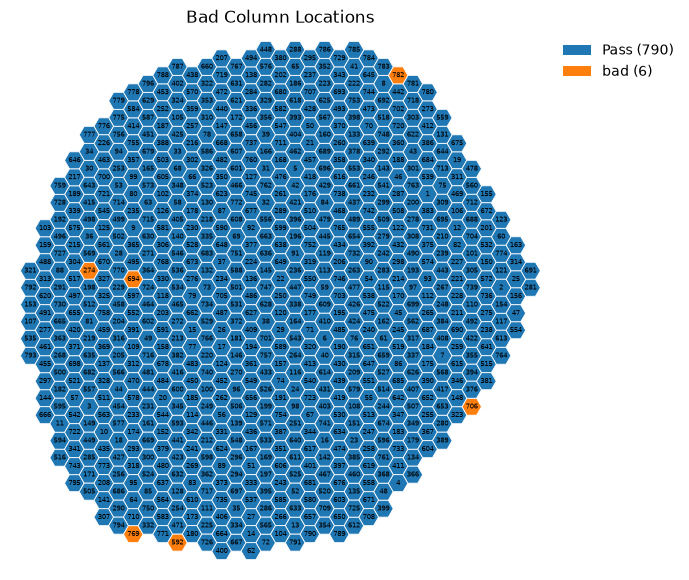

In [17]:
# Visualizing bad columns
bad_df = ref.filter(pl.col('t0_source') == 'none') 
view = columns_df.with_columns(
    pl.when(pl.col('column_id').is_in(bad_columns)).then(pl.lit('bad')).otherwise(pl.lit('Pass')).alias('quality')
)

cnx.viz.hexmap(view, values='quality', annotate='column_id')
plt.title('Bad Column Locations')
plt.savefig('bad_col_locs.png')

In [18]:
# Flood filling of the bad columns with depth 
t0 = dict(zip(ref['column_id'], ref['t0']))
src = dict(zip(ref['column_id'], ref['t0_source']))
sep = dict(zip(ref['column_id'], ref['sep']))
n_deep = dict(zip(ref['column_id'], ref['n_deep']))
n_shallow = dict(zip(ref['column_id'], ref['n_shallow']))
# Have by_pq going from (p, q) -> cid 
pq = {c: k for k, c in by_pq.items()}

# Flood filling 
changed = True
while changed:
    changed = False 
    for c in t0:
        if c not in pq or src[c] != 'none':
            continue
        # Grab neighboring values
        t_nb = [t0[by_pq[x]] for x in cnx.viz.hex_neighbors(*pq[c]) if (x in by_pq) and (src[by_pq[x]] != 'none')]
        sep_nb = [sep[by_pq[x]] for x in cnx.viz.hex_neighbors(*pq[c]) if (x in by_pq) and (src[by_pq[x]] != 'none')]
        n_deep_nb = [n_deep[by_pq[x]] for x in cnx.viz.hex_neighbors(*pq[c]) if (x in by_pq) and (src[by_pq[x]] != 'none')]
        n_shallow_nb = [n_shallow[by_pq[x]] for x in cnx.viz.hex_neighbors(*pq[c]) if (x in by_pq) and (src[by_pq[x]] != 'none')]
        if nb:
            t0[c] = float(np.median(t_nb))
            src[c] = 'neighbors'
            sep[c] = float(np.median(sep_nb))
            n_deep[c] = float(np.median(n_deep_nb))
            n_shallow[c] = float(np.median(n_shallow_nb))
            changed = True

# Print out any missing columns
print(f'Still missing depth: ',  [c for c, s in src.items() if s == 'none'])

# Write new orientations back in 
ref = ref.with_columns(
    pl.col('column_id').replace_strict(t0).alias('t0'),
    pl.col('column_id').replace_strict(src).alias('t0_source'),
    pl.col('column_id').replace_strict(sep).alias('sep'),
    pl.col('column_id').replace_strict(n_deep).alias('n_deep'),
    pl.col('column_id').replace_strict(n_shallow).alias('n_shallow')
)

Still missing depth:  []


In [19]:
# Grabbing depths relative to m5 position for each landmark synapse 
depth_df = depth_df.drop([c for c in ('t0', 't0_source', 'depth') if c in depth_df.columns])
depth_df = (depth_df.join(ref.select('column_id', 't0', 't0_source', 'sep', 'n_deep', 'n_shallow'), on='column_id')
            .with_columns((pl.col('t') - pl.col('t0')).alias('depth'))
            )

healthy-R7 columns: 615; offset median 4.19 um, 
IQR [3.71, 4.75]; 
Mean: 4.20 Var: 1.25; 
Negative offset columns: [694 543 475]


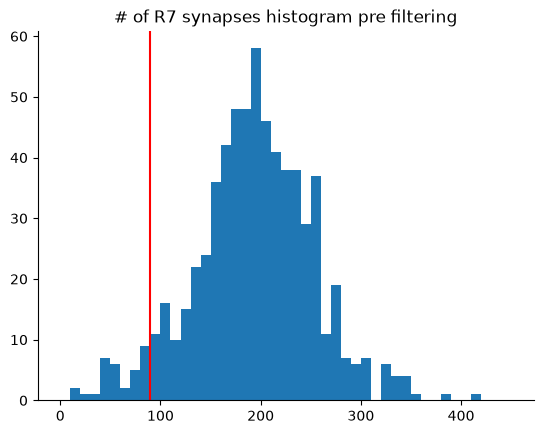

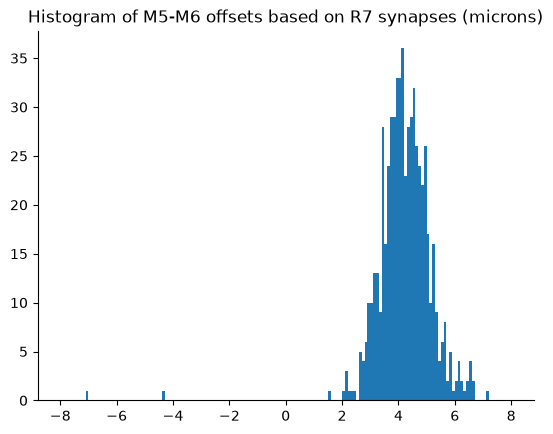

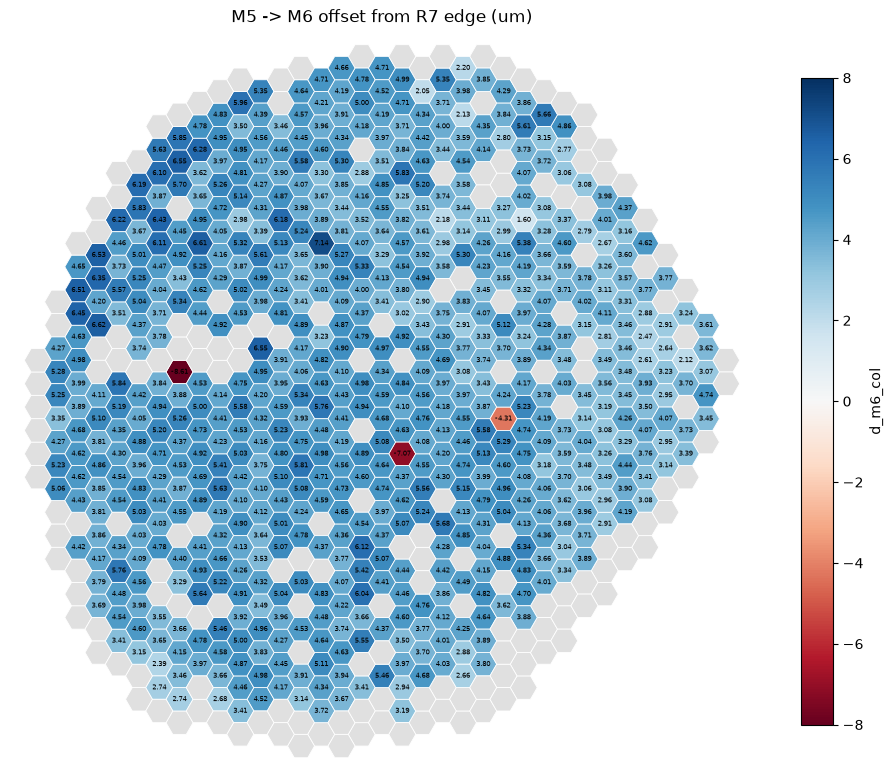

In [20]:
# Visualzing R7 synapses into M6 as a function of depth
r7_edge = (
    depth_df.filter((pl.col('type') == 'R7') & (pl.col('role') == 'pre'))
    .group_by('column_id').agg(pl.col('depth').quantile(0.95).alias('d_m6_col'), pl.len().alias('n_r7'))
)

plt.hist(r7_edge['n_r7'], bins=np.linspace(0, 450, 46));
plt.axvline(x=np.percentile(r7_edge['n_r7'], 5), color='red')
plt.title('# of R7 synapses histogram pre filtering')
sns.despine();

# Eyeball 100 synapses as the 5th percentile
r7_edge = r7_edge.filter(pl.col('n_r7') >= 100)


print(f"healthy-R7 columns: {r7_edge.height}; offset median {r7_edge['d_m6_col'].median():.2f} um, "
      "\n"
      f"IQR [{r7_edge['d_m6_col'].quantile(0.25):.2f}, {r7_edge['d_m6_col'].quantile(0.75):.2f}]; "
      "\n"
      f"Mean: {r7_edge['d_m6_col'].mean():.2f} Var: {r7_edge['d_m6_col'].var():.2f}; "
      "\n"
      f"Negative offset columns: {r7_edge.filter(pl.col('d_m6_col') < 0)['column_id'].to_numpy().squeeze()}")

# Histogram of offsets 
fig, ax = plt.subplots()
plt.hist(r7_edge['d_m6_col'], bins=np.linspace(-8, 8, 161))
plt.title('Histogram of M5-M6 offsets based on R7 synapses (microns)')
sns.despine()

fig, ax = plt.subplots(figsize=(12, 12))
view = columns_df.join(r7_edge, on='column_id', how='left')
cnx.viz.hexmap(view, 'd_m6_col', annotate='d_m6_col', fmt='.2f', ax=ax,
               cmap="RdBu", vmin=-8, vmax=8, title="M5 -> M6 offset from R7 edge (um)")
plt.savefig('M5_M6_offfsets_R7_synapses.png', bbox_inches='tight')


In [21]:
# Looking at pooled offset values
pq_all = columns_df.select('column_id', 'p' ,'q')
pq_coords = pq_all.select('p', 'q').to_numpy().squeeze().astype(float)
dists = cnx.viz.hex_distance(pq_coords[:, None, :], pq_coords[None, :, :])
edge_map = dict(zip(r7_edge['column_id'], r7_edge['d_m6_col']))
vals = np.array([edge_map.get(c, np.nan) for c in pq_all["column_id"]])
d_m6_local = np.array([np.nanmedian(vals[(dists[i] <= 2) & ~np.isnan(vals)]) if np.any((dists[i] <= 2) & ~np.isnan(vals)) else np.nan
                       for i in range(len(vals))])
d_m6_global = float(r7_edge["d_m6_col"].median())
d_m6_local = np.where(np.isnan(d_m6_local), d_m6_global, d_m6_local)   # isolated columns fall back to global
ref = ref.join(pl.DataFrame({"column_id": pq_all["column_id"], "d_m6": d_m6_local}), on="column_id")
print(f"local offset range {d_m6_local.min():.2f}..{d_m6_local.max():.2f} um (global median {d_m6_global:.2f})")


local offset range 2.66..6.22 um (global median 4.19)


In [22]:
# Depth relative to M6 (negative = distal), for every landmark synapse
depth_df = depth_df.join(ref.select("column_id", "d_m6"), on="column_id").with_columns(
    (pl.col("depth") - pl.col("d_m6")).alias("depth_m6")
)

In [23]:
# Where do the rulers disagree with the R7 synapses
diag = (r7_edge.join(ref.select("column_id", "d_m6"), on="column_id")
        .with_columns((pl.col("d_m6_col") - pl.col("d_m6")).alias("r7_residual"))
        .filter(pl.col("r7_residual").abs() > 3))
print(f"R7 edge disagrees with ruler by > 3 um in {diag.height} columns:", diag["column_id"].to_list()[:20])

R7 edge disagrees with ruler by > 3 um in 4 columns: [694, 543, 466, 475]


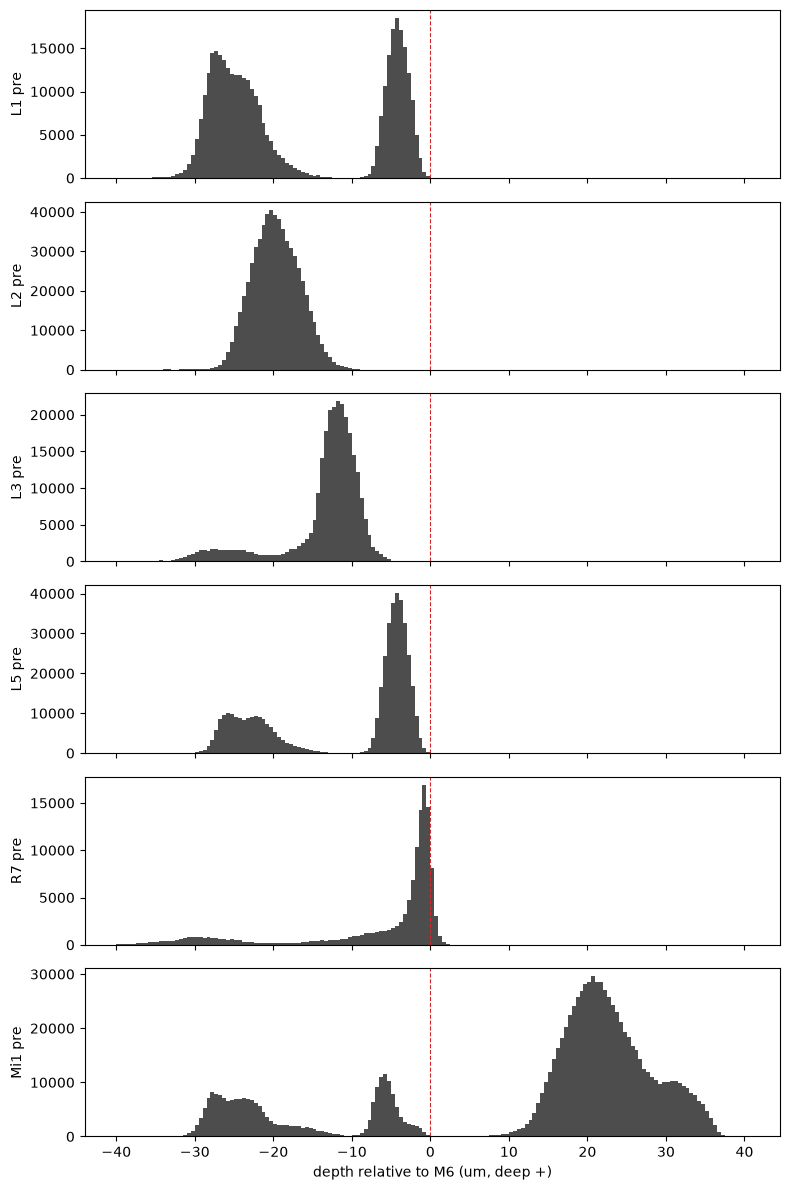

In [ ]:
# For each column, grab the distribution of the synapses depths relative to m6
interior = ref.filter((pl.col("t0_source") == "L1") | (pl.col("t0_source") == 'L5'))["column_id"].to_list()
pool = depth_df.filter(pl.col("column_id").is_in(interior))
landmarks = [("L1", "pre"), ("L2", "pre"), ("L3", "pre"), ("L5", "pre"), ("R7", "pre"), ("Mi1", "pre")]
bins = np.arange(-40, 41, 0.5)
fig, axs = plt.subplots(len(landmarks), 1, figsize=(8, 2 * len(landmarks)), sharex=True, layout="tight")
for ax, (typ, role) in zip(axs, landmarks):
    d = pool.filter((pl.col("type") == typ) & (pl.col("role") == role))["depth_m6"].to_numpy()
    ax.hist(d, bins=bins, color="0.3"); ax.axvline(0, color="tab:red", ls="--", lw=0.8)
    ax.set_ylabel(f"{typ} {role}")
axs[-1].set_xlabel("depth relative to M6 (um, deep +)")
plt.savefig('landmark_dists_rel_m6.png', bbox_inches='tight')

n = 786, r = -0.964, slope = -0.78, intercept = 0.60


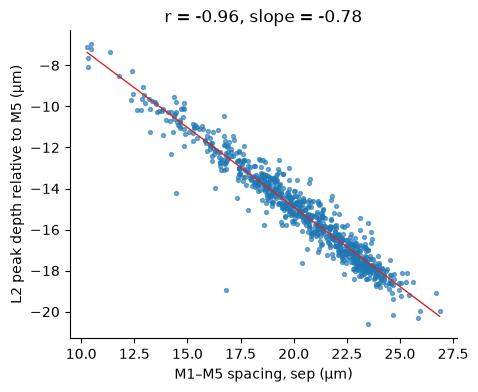

In [ ]:
# Is the L2 output synapse location smear correlate with the separation distance smear? 
# If yes, we have a per column effect. If no then another effect 
l2 = (depth_df.filter((pl.col("type") == "L2") & (pl.col("role") == "pre"))
      .group_by("column_id").agg(pl.col("depth").median().alias("l2_peak"), pl.len().alias("n_l2"))
      .filter(pl.col("n_l2") >= 50)
      .join(ref.select("column_id", "sep"), on="column_id"))

x = l2["sep"].to_numpy()
y = l2["l2_peak"].to_numpy()
slope, intercept = np.polyfit(x, y, 1)
r = np.corrcoef(x, y)[0, 1]
print(f"n = {len(x)}, r = {r:.3f}, slope = {slope:.2f}, intercept = {intercept:.2f}")

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(x, y, s=8, alpha=0.6)
xx = np.array([x.min(), x.max()])
ax.plot(xx, slope * xx + intercept, color="tab:red", lw=1)
ax.set_xlabel("M1–M5 spacing, sep (µm)")
ax.set_ylabel("L2 peak depth relative to M5 (µm)")
ax.set_title(f"r = {r:.2f}, slope = {slope:.2f}")
sns.despine();

overall own-column fraction: 0.859


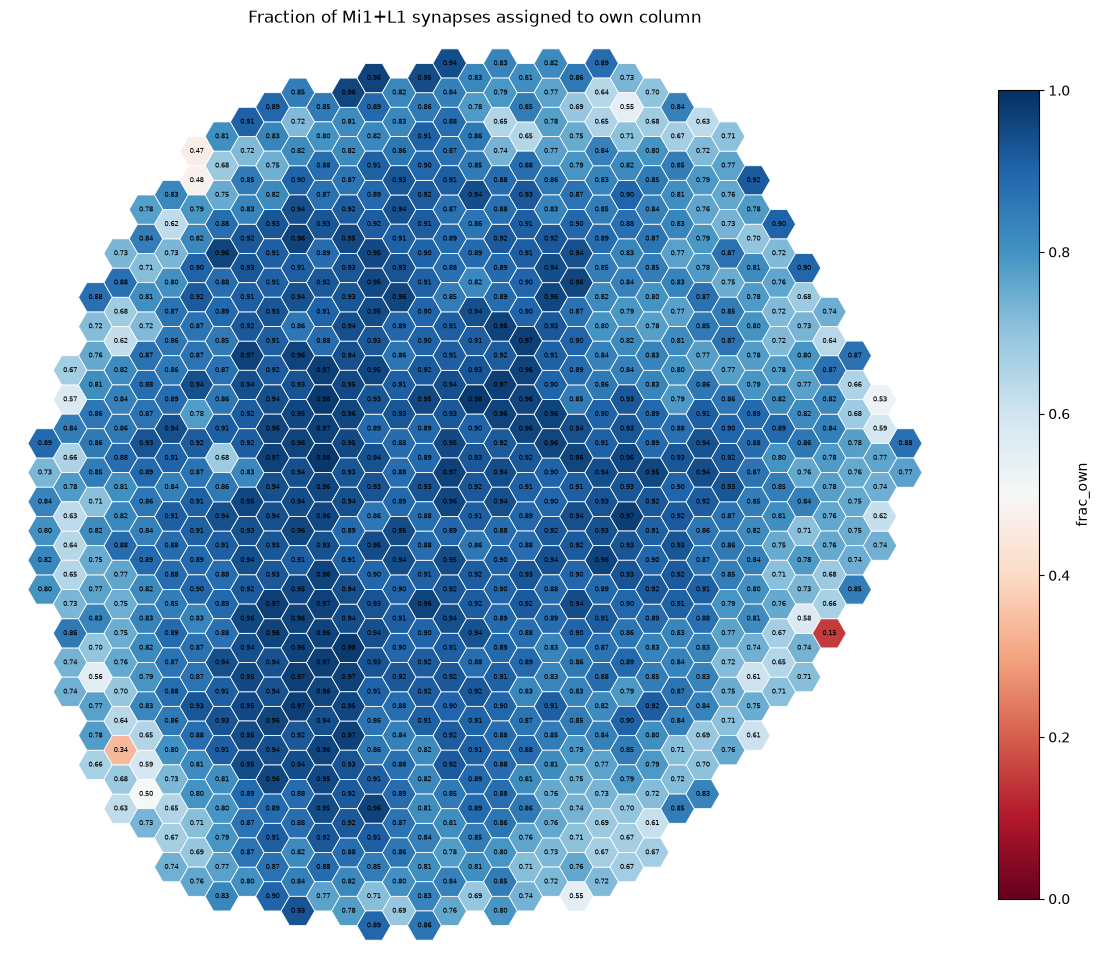

In [96]:
# Building a lookup table for each point. Goes from point -> column + depth
from scipy.spatial import cKDTree

axes = oriented_df.join(ref.select('column_id', 't0'), on='column_id')
step_um = 0.5

samples, sample_col, sample_depth = [], [], []
for r in axes.iter_rows(named=True):
    t = np.arange(r['t_1'], r['t_99'] + step_um, step_um)
    c = np.array([r['cx'], r['cy'], r['cz']])
    u = np.array([r['ux'], r['uy'], r['uz']])
    samples.append(c + t[:, None] * u)
    sample_col.append(np.full(len(t), r['column_id']))
    sample_depth.append(t - r['t0'])
samples = np.vstack(samples)
sample_col = np.concatenate(sample_col)
sample_depth = np.concatenate(sample_depth)
tree = cKDTree(samples)

def locate(point_um, max_dist=5.0):
    """Nearest column axis of points (n, 3) in um.

    Returns column_id, depth, and distance to the axis. 
    Points farther than max dist get column_id -1 and nan depth.
    """
    xyz_um = np.atleast_2d(point_um)
    dist, idx = tree.query(xyz_um)
    col = np.where(dist <= max_dist, sample_col[idx], -1)
    depth = np.where(dist <= max_dist, sample_depth[idx], np.nan)
    return col, depth, dist 

# Check if the lookup table properly assigns the landmark synapses 
test = depth_df.filter(pl.col('type').is_in(['Mi1', 'L1']))
test_col, test_depth, test_dist = locate(test.select('x', 'y', 'z').to_numpy().squeeze())
test_results = test.with_columns(pl.Series("col_found", test_col), pl.Series("depth_found", test_depth), pl.Series("dist", test_dist))
agree = test_results.group_by("column_id").agg((pl.col("col_found") == pl.col("column_id")).mean().alias("frac_own"),
                                      (pl.col("depth_found") - pl.col("depth")).abs().median().alias("depth_err"))
print(f"overall own-column fraction: {(test_results['col_found'] == test_results['column_id']).mean():.3f}")
fig, ax = plt.subplots(figsize=(15,15))
cnx.viz.hexmap(columns_df.join(agree, on='column_id'), 'frac_own', annotate='frac_own', fmt='.2f', ax=ax, cmap="RdBu", vmin=0.0, vmax=1,
               title="Fraction of Mi1+L1 synapses assigned to own column");
# plt.savefig('Fraction_mi1_l1_syn_recov.png', bbox_inches='tight', dpi=180)

In [115]:
# Could axes be intersecting? 
pq_of = {r["column_id"]: (r["p"], r["q"]) for r in ref.iter_rows(named=True)}
col_of_pq = {v: k for k, v in pq_of.items()}
rows = []
for c, (p, q) in pq_of.items():
    mine = samples[sample_col == c]
    for n in cnx.viz.hex_neighbors(p, q):
        if n not in col_of_pq:
            continue
        theirs = samples[sample_col == col_of_pq[n]]
        d = np.linalg.norm(mine[:, None, :] - theirs[None, :, :], axis=2)     # all pairs of samples
        i, j = np.unravel_index(np.argmin(d), d.shape)
        rows.append((c, col_of_pq[n], float(d[i, j]), float(sample_depth[sample_col == c][i])))
approach = pl.DataFrame(rows, schema=["column_id", "neighbour", "min_dist_um", "depth_at_min"], orient="row")
with pl.Config(tbl_rows=-1):
    print(approach["min_dist_um"].describe())
    print(approach.filter(pl.col("min_dist_um") < 3).sort("min_dist_um"))

shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆ value     │
│ ---        ┆ ---       │
│ str        ┆ f64       │
╞════════════╪═══════════╡
│ count      ┆ 4564.0    │
│ null_count ┆ 0.0       │
│ mean       ┆ 6.313758  │
│ std        ┆ 1.447953  │
│ min        ┆ 0.261071  │
│ 25%        ┆ 5.268576  │
│ 50%        ┆ 6.190413  │
│ 75%        ┆ 7.394731  │
│ max        ┆ 16.882046 │
└────────────┴───────────┘
shape: (42, 4)
┌───────────┬───────────┬─────────────┬──────────────┐
│ column_id ┆ neighbour ┆ min_dist_um ┆ depth_at_min │
│ ---       ┆ ---       ┆ ---         ┆ ---          │
│ i64       ┆ i64       ┆ f64         ┆ f64          │
╞═══════════╪═══════════╪═════════════╪══════════════╡
│ 314       ┆ 774       ┆ 0.261071    ┆ 5.56203      │
│ 774       ┆ 314       ┆ 0.261071    ┆ 5.541277     │
│ 159       ┆ 103       ┆ 0.559975    ┆ -13.309204   │
│ 103       ┆ 159       ┆ 0.559975    ┆ -11.904972   │
│ 516       ┆ 341       ┆ 1.882633    ┆ -39.101263   │
│ 341       ┆ 51

In [88]:
# Why is this so low? 
bins = np.arange(-35, 40, 5)
by_depth = (test_results.with_columns(((pl.col("depth") // 5) * 5).alias("depth_bin"))
            .group_by("depth_bin").agg((pl.col("col_found") == pl.col("column_id")).mean().alias("frac_own"), pl.len().alias("n"))
            .sort("depth_bin"))
with pl.Config(tbl_rows=-1):
    print(by_depth)
win = test_results.filter(pl.col("depth").is_between(-25, 5))    # M1 through M6, the region the marker tests use
print("own-column fraction in M1..M6:", (win["col_found"] == win["column_id"]).mean())

shape: (21, 3)
┌───────────┬──────────┬────────┐
│ depth_bin ┆ frac_own ┆ n      │
│ ---       ┆ ---      ┆ ---    │
│ f64       ┆ f64      ┆ u32    │
╞═══════════╪══════════╪════════╡
│ -65.0     ┆ 0.0      ┆ 9      │
│ -55.0     ┆ 0.0      ┆ 10     │
│ -50.0     ┆ 0.0      ┆ 25     │
│ -45.0     ┆ 0.009174 ┆ 109    │
│ -40.0     ┆ 0.056863 ┆ 510    │
│ -35.0     ┆ 0.146232 ┆ 1778   │
│ -30.0     ┆ 0.873444 ┆ 27956  │
│ -25.0     ┆ 0.927471 ┆ 311297 │
│ -20.0     ┆ 0.850572 ┆ 211099 │
│ -15.0     ┆ 0.710973 ┆ 46352  │
│ -10.0     ┆ 0.878368 ┆ 12546  │
│ -5.0      ┆ 0.802664 ┆ 192970 │
│ 0.0       ┆ 0.774295 ┆ 136993 │
│ 5.0       ┆ 0.889139 ┆ 1335   │
│ 10.0      ┆ 0.868917 ┆ 5302   │
│ 15.0      ┆ 0.89306  ┆ 79746  │
│ 20.0      ┆ 0.882009 ┆ 255883 │
│ 25.0      ┆ 0.880137 ┆ 265796 │
│ 30.0      ┆ 0.85256  ┆ 129042 │
│ 35.0      ┆ 0.832294 ┆ 80969  │
│ 40.0      ┆ 0.772021 ┆ 6891   │
└───────────┴──────────┴────────┘
own-column fraction in M1..M6: 0.8485114517638822


In [89]:
by_dist = (test_results.with_columns(pl.col("dist").clip(0, 6).floor().alias("dist_bin"))
           .group_by("dist_bin").agg((pl.col("col_found") == pl.col("column_id")).mean().alias("frac_own"), pl.len().alias("n"))
           .sort("dist_bin"))
print(by_dist)

shape: (7, 3)
┌──────────┬──────────┬────────┐
│ dist_bin ┆ frac_own ┆ n      │
│ ---      ┆ ---      ┆ ---    │
│ f64      ┆ f64      ┆ u32    │
╞══════════╪══════════╪════════╡
│ 0.0      ┆ 0.962087 ┆ 129296 │
│ 1.0      ┆ 0.940437 ┆ 488506 │
│ 2.0      ┆ 0.867261 ┆ 683605 │
│ 3.0      ┆ 0.756422 ┆ 386172 │
│ 4.0      ┆ 0.651666 ┆ 74440  │
│ 5.0      ┆ 0.0      ┆ 3551   │
│ 6.0      ┆ 0.0      ┆ 1048   │
└──────────┴──────────┴────────┘


shape: (7, 4)
┌──────┬──────────┬───────────────────┬─────┐
│ type ┆ frac_own ┆ n_cells_elsewhere ┆ len │
│ ---  ┆ ---      ┆ ---               ┆ --- │
│ str  ┆ f64      ┆ u32               ┆ u32 │
╞══════╪══════════╪═══════════════════╪═════╡
│ Mi1  ┆ 0.863241 ┆ 4                 ┆ 796 │
│ L3   ┆ 0.806723 ┆ 28                ┆ 736 │
│ R8   ┆ 0.920502 ┆ 14                ┆ 654 │
│ L5   ┆ 0.739073 ┆ 31                ┆ 778 │
│ R7   ┆ 0.897959 ┆ 37                ┆ 659 │
│ L1   ┆ 0.903475 ┆ 10                ┆ 789 │
│ L2   ┆ 0.978033 ┆ 7                 ┆ 789 │
└──────┴──────────┴───────────────────┴─────┘


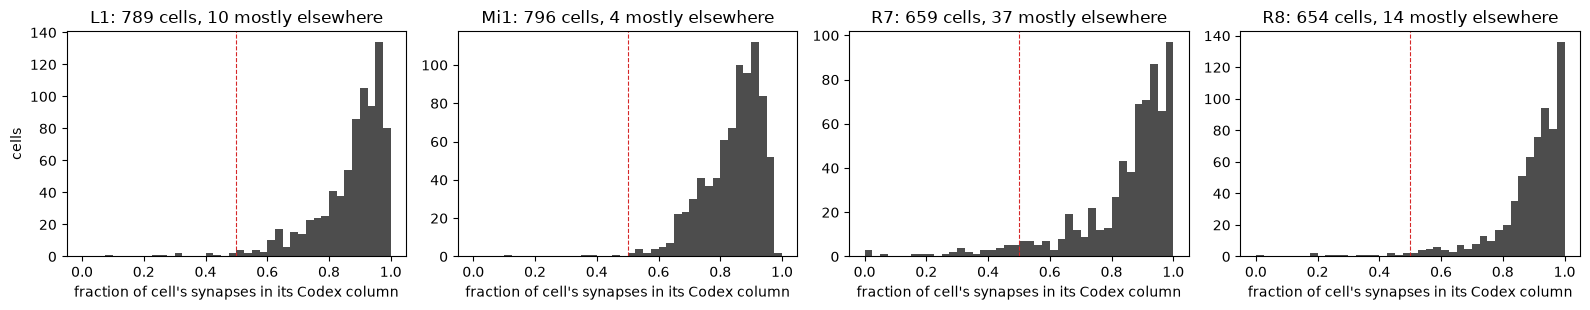

In [103]:
a, b, c = locate(depth_df.select('x', 'y', 'z').to_numpy().squeeze())
chk = depth_df.with_columns(pl.Series("col_found", a), pl.Series("depth_found", b), pl.Series("dist", c))

chk = chk.with_columns(pl.when(pl.col("role") == "pre").then(pl.col("pre")).otherwise(pl.col("post")).alias("cell"))
per_cell = (chk.group_by("cell", "type", "column_id")
            .agg((pl.col("col_found") == pl.col("column_id")).mean().alias("frac_own"),
                 pl.col("col_found").mode().first().alias("col_majority"), pl.len().alias("n")))
print(per_cell.group_by("type").agg(pl.col("frac_own").median(), (pl.col("frac_own") < 0.5).sum().alias("n_cells_elsewhere"), pl.len()))

types = ["L1", "Mi1", "R7", "R8"]  
fig, axs = plt.subplots(1, len(types), figsize=(4 * len(types), 3.2), sharey=False, layout="tight")
bins = np.linspace(0, 1, 41)
for ax, typ in zip(axs, types):
    f = per_cell.filter(pl.col("type") == typ)["frac_own"].to_numpy()
    ax.hist(f, bins=bins, color="0.3")
    ax.axvline(0.5, color="tab:red", ls="--", lw=0.8)
    ax.set_title(f"{typ}: {len(f)} cells, {(f < 0.5).sum()} mostly elsewhere")
    ax.set_xlabel("fraction of cell's synapses in its Codex column")
axs[0].set_ylabel("cells")
plt.savefig('per_cell_hist.png')

shape: (7, 4)
┌──────┬─────────────────┬───────────────────┬─────────┐
│ type ┆ median_frac_own ┆ n_cells_elsewhere ┆ n_cells │
│ ---  ┆ ---             ┆ ---               ┆ ---     │
│ str  ┆ f64             ┆ u32               ┆ u32     │
╞══════╪═════════════════╪═══════════════════╪═════════╡
│ L1   ┆ 0.903475        ┆ 10                ┆ 789     │
│ L2   ┆ 0.978033        ┆ 7                 ┆ 789     │
│ L3   ┆ 0.806723        ┆ 28                ┆ 736     │
│ L5   ┆ 0.739073        ┆ 31                ┆ 778     │
│ Mi1  ┆ 0.863241        ┆ 4                 ┆ 796     │
│ R7   ┆ 0.897959        ┆ 37                ┆ 659     │
│ R8   ┆ 0.920502        ┆ 14                ┆ 654     │
└──────┴─────────────────┴───────────────────┴─────────┘


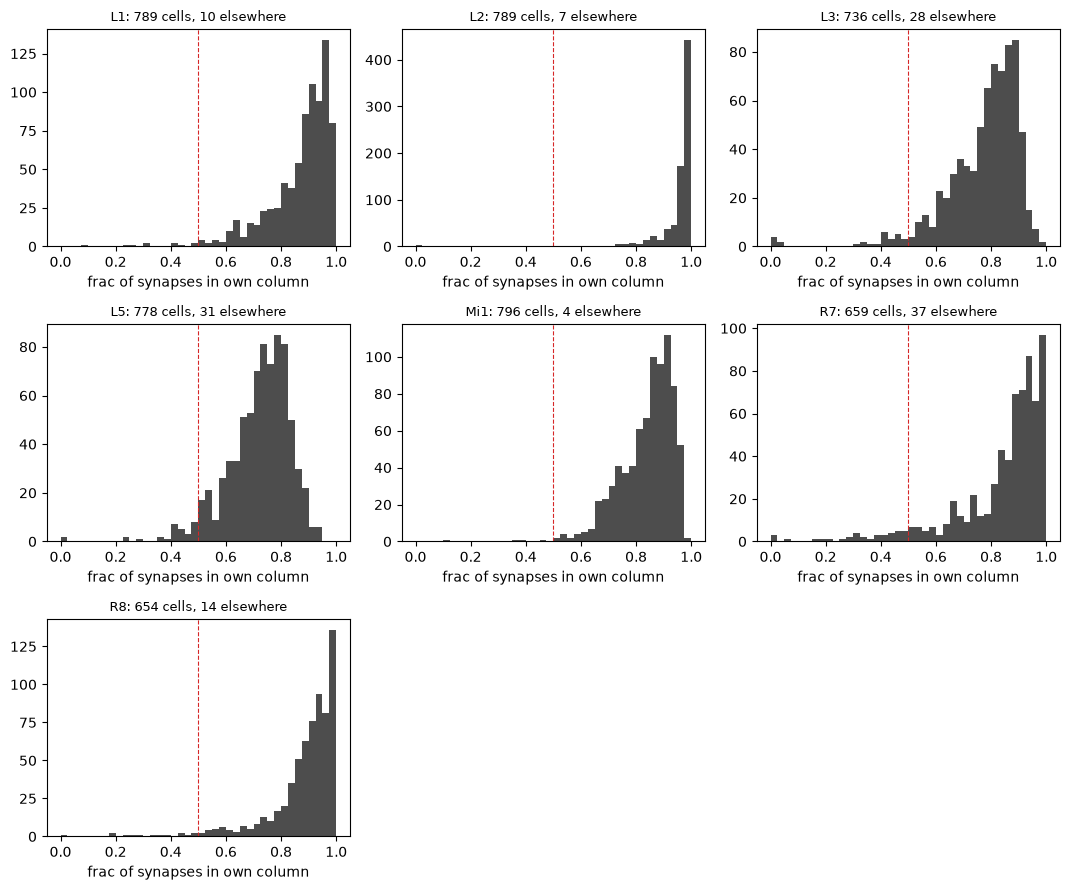

In [131]:
# Tests of curvature 
col, dep, dist = locate(depth_df.select("x", "y", "z").to_numpy())
chk = depth_df.with_columns(
    pl.Series("col_found", col), pl.Series("depth_found", dep), pl.Series("dist", dist),
    pl.when(pl.col("role") == "pre").then(pl.col("pre")).otherwise(pl.col("post")).alias("cell"),
)
per_cell = (chk.group_by("cell", "type", "column_id")
            .agg((pl.col("col_found") == pl.col("column_id")).mean().alias("frac_own"),
                 pl.col("col_found").mode().first().alias("col_majority"), pl.len().alias("n")))
summary = (per_cell.group_by("type")
           .agg(pl.col("frac_own").median().alias("median_frac_own"),
                (pl.col("frac_own") < 0.5).sum().alias("n_cells_elsewhere"), pl.len().alias("n_cells"))
           .sort("type"))
print(summary)

types = summary["type"].to_list()
n_cols = int(np.ceil(np.sqrt(len(types))))
n_rows = int(np.ceil(len(types) / n_cols))
fig, axs = plt.subplots(n_rows, n_cols, figsize=(3.6 * n_cols, 3 * n_rows), layout="tight")
axs = np.atleast_1d(axs).ravel()                      # one flat list of panels, whatever the grid shape
for ax, typ in zip(axs, types):
    f = per_cell.filter(pl.col("type") == typ)["frac_own"].to_numpy()
    ax.hist(f, bins=np.linspace(0, 1, 41), color="0.3")
    ax.axvline(0.5, color="tab:red", ls="--", lw=0.8)
    ax.set_title(f"{typ}: {len(f)} cells, {(f < 0.5).sum()} elsewhere", fontsize=9)
    ax.set_xlabel("frac of synapses in own column")
for ax in axs[len(types):]:                           # blank the leftover panels
    ax.set_axis_off()
fig.savefig("Per_cell_median_frac_own_syns_hist.png", bbox_inches="tight")

shape: (17, 4)
┌───────────┬───────────┬──────────┬────────┐
│ depth_bin ┆ median_um ┆ p90_um   ┆ n_cols │
│ ---       ┆ ---       ┆ ---      ┆ ---    │
│ f64       ┆ f64       ┆ f64      ┆ u32    │
╞═══════════╪═══════════╪══════════╪════════╡
│ -40.0     ┆ 3.536162  ┆ 3.536162 ┆ 1      │
│ -35.0     ┆ 2.252751  ┆ 3.293103 ┆ 17     │
│ -30.0     ┆ 1.431497  ┆ 2.693403 ┆ 309    │
│ -25.0     ┆ 0.613998  ┆ 1.651577 ┆ 676    │
│ -20.0     ┆ 0.552314  ┆ 1.169505 ┆ 777    │
│ -15.0     ┆ 0.665369  ┆ 1.35863  ┆ 794    │
│ -10.0     ┆ 0.969272  ┆ 1.779363 ┆ 787    │
│ -5.0      ┆ 0.99071   ┆ 1.566479 ┆ 790    │
│ 0.0       ┆ 0.865215  ┆ 1.56385  ┆ 787    │
│ 5.0       ┆ 1.185292  ┆ 2.453649 ┆ 65     │
│ 10.0      ┆ 1.046144  ┆ 2.698905 ┆ 33     │
│ 15.0      ┆ 0.900211  ┆ 1.840349 ┆ 334    │
│ 20.0      ┆ 0.768383  ┆ 1.505365 ┆ 756    │
│ 25.0      ┆ 0.714582  ┆ 1.810365 ┆ 708    │
│ 30.0      ┆ 0.816843  ┆ 1.668009 ┆ 562    │
│ 35.0      ┆ 1.033557  ┆ 1.777344 ┆ 364    │
│ 40.0      ┆ 1.430

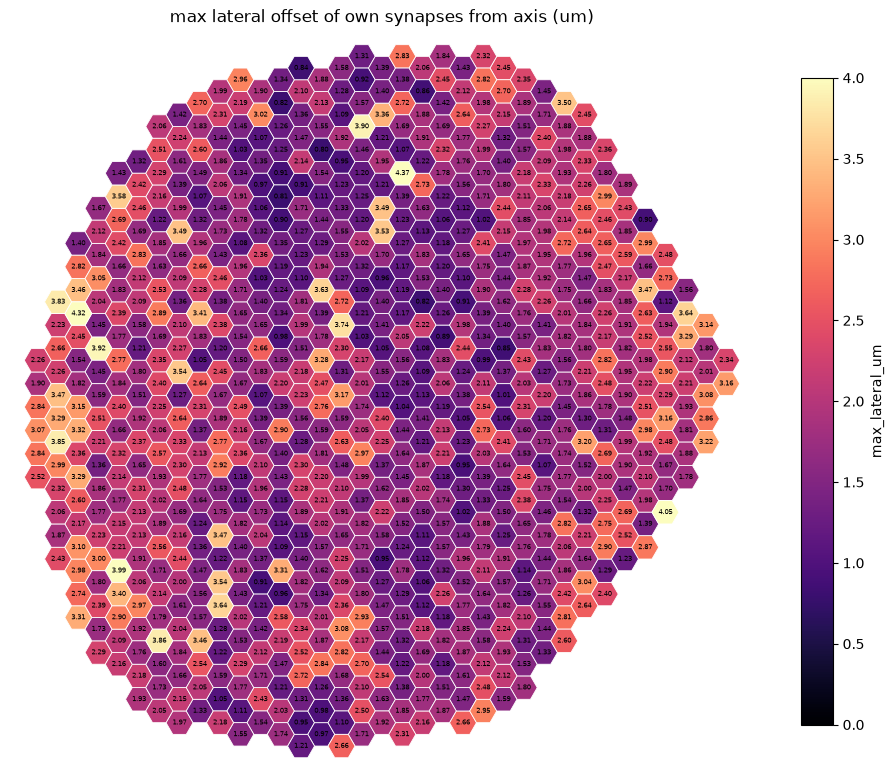

In [126]:
own = (chk.filter(pl.col("col_found") == pl.col("column_id"))
       .join(axes.select("column_id", "cx", "cy", "cz", "ux", "uy", "uz"), on="column_id")
       .with_columns(((pl.col("depth") / 5).floor() * 5).alias("depth_bin")))
cent = (own.group_by("column_id", "depth_bin")
        .agg(pl.col("x").mean(), pl.col("y").mean(), pl.col("z").mean(), pl.col("t").mean().alias("t_mean"),
             *[pl.col(k).first() for k in ("cx", "cy", "cz", "ux", "uy", "uz")], pl.len().alias("n"))
        .filter(pl.col("n") >= 20))
P = cent.select("x", "y", "z").to_numpy()
C = cent.select("cx", "cy", "cz").to_numpy()
U = cent.select("ux", "uy", "uz").to_numpy()
axis_pt = C + cent["t_mean"].to_numpy()[:, None] * U                 # the axis point at that bin's depth
cent = cent.with_columns(pl.Series("lateral_um", np.linalg.norm(P - axis_pt, axis=1)))
offset_by_depth = (cent.group_by("depth_bin")
                   .agg(pl.col("lateral_um").median().alias("median_um"),
                        pl.col("lateral_um").quantile(0.9).alias("p90_um"), pl.len().alias("n_cols"))
                   .sort("depth_bin"))
with pl.Config(tbl_rows=-1):
     print(offset_by_depth)
worst = cent.group_by("column_id").agg(pl.col("lateral_um").max().alias("max_lateral_um"))
fig, ax = plt.subplots(figsize=(12, 12))
plot_df = columns_df.join(worst, on='column_id', how='left')
cnx.viz.hexmap(plot_df, 'max_lateral_um', annotate='max_lateral_um', fmt='.2f', cmap="magma", vmin=0, vmax=4,
               title="max lateral offset of own synapses from axis (um)", ax=ax)
plt.savefig('Max_lat_disp.png', dpi=180)

shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆ value     │
│ ---        ┆ ---       │
│ str        ┆ f64       │
╞════════════╪═══════════╡
│ count      ┆ 2282.0    │
│ null_count ┆ 0.0       │
│ mean       ┆ 6.313758  │
│ std        ┆ 1.448112  │
│ min        ┆ 0.261071  │
│ 25%        ┆ 5.268576  │
│ 50%        ┆ 6.190413  │
│ 75%        ┆ 7.394731  │
│ max        ┆ 16.882046 │
└────────────┴───────────┘
pairs closer than 3 um: 21 of 2282
shape: (21, 4)
┌───────────┬───────────┬─────────────┬──────────────┐
│ column_id ┆ neighbour ┆ min_dist_um ┆ depth_at_min │
│ ---       ┆ ---       ┆ ---         ┆ ---          │
│ i64       ┆ i64       ┆ f64         ┆ f64          │
╞═══════════╪═══════════╪═════════════╪══════════════╡
│ 314       ┆ 774       ┆ 0.261071    ┆ 5.56203      │
│ 103       ┆ 159       ┆ 0.559975    ┆ -11.904972   │
│ 341       ┆ 516       ┆ 1.882633    ┆ -35.776477   │
│ 381       ┆ 394       ┆ 2.015754    ┆ -21.99484    │
│ 397       ┆ 467       ┆ 2.17941   

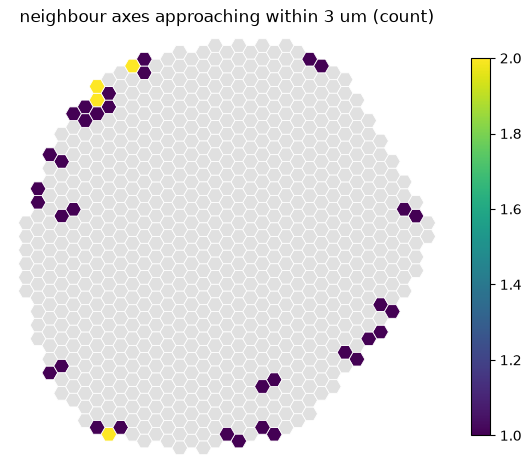

In [129]:
pq_of = {r["column_id"]: (r["p"], r["q"]) for r in ref.iter_rows(named=True)}
col_of_pq = {v: k for k, v in pq_of.items()}
rows = []
for c, (p, q) in pq_of.items():
    mine = samples[sample_col == c]
    mine_depth = sample_depth[sample_col == c]
    for nb in cnx.viz.hex_neighbors(p, q):
        if nb not in col_of_pq or col_of_pq[nb] < c:                  # each pair once
            continue
        theirs = samples[sample_col == col_of_pq[nb]]
        d = np.linalg.norm(mine[:, None, :] - theirs[None, :, :], axis=2)
        i, j = np.unravel_index(np.argmin(d), d.shape)
        rows.append((c, col_of_pq[nb], float(d[i, j]), float(mine_depth[i])))
approach = pl.DataFrame(rows, schema=["column_id", "neighbour", "min_dist_um", "depth_at_min"], orient="row")
close = approach.filter(pl.col("min_dist_um") < 3)
with pl.Config(tbl_rows=-1):
    print(approach["min_dist_um"].describe())
    print("pairs closer than 3 um:", close.height, "of", approach.height)
    print(close.sort("min_dist_um"))
n_bad = pl.concat([close.select(pl.col("column_id").alias("c")), close.select(pl.col("neighbour").alias("c"))]).group_by("c").len()
cnx.viz.hexmap(columns_df, dict(zip(n_bad["c"], n_bad["len"])), title="neighbour axes approaching within 3 um (count)")
plt.savefig('approach_test.png')

In [134]:
pq_map = {r["column_id"]: (r["p"], r["q"]) for r in ref.iter_rows(named=True)}
moved = (per_cell.filter((pl.col("type").is_in(["R7", "R8"])) & (pl.col("frac_own") < 0.5))
         .with_columns(pl.struct(["column_id", "col_majority"]).map_elements(
             lambda s: float(cnx.viz.hex_distance(pq_map[s["column_id"]], pq_map[s["col_majority"]])) if s["col_majority"] in pq_map else float("nan"),
             return_dtype=pl.Float64).alias("lattice_dist")))
frac_major = (chk.filter(pl.col("type").is_in(["R7", "R8"])).group_by("cell")
              .agg((pl.col("col_found") == pl.col("col_found").mode().first()).mean().alias("frac_majority")))
moved = moved.join(frac_major, on="cell").sort("type", "frac_own")
with pl.Config(tbl_rows=-1):
    print(moved.select("cell", "type", "column_id", "col_majority", "lattice_dist", "frac_own", "frac_majority", "n"))

shape: (51, 8)
┌───────────────┬──────┬───────────┬──────────────┬──────────────┬───────────┬───────────────┬─────┐
│ cell          ┆ type ┆ column_id ┆ col_majority ┆ lattice_dist ┆ frac_own  ┆ frac_majority ┆ n   │
│ ---           ┆ ---  ┆ ---       ┆ ---          ┆ ---          ┆ ---       ┆ ---           ┆ --- │
│ i64           ┆ str  ┆ u16       ┆ i64          ┆ f64          ┆ f64       ┆ f64           ┆ u32 │
╞═══════════════╪══════╪═══════════╪══════════════╪══════════════╪═══════════╪═══════════════╪═════╡
│ 7205759406268 ┆ R7   ┆ 670       ┆ 327          ┆ 1.0          ┆ 0.0       ┆ 1.0           ┆ 102 │
│ 49226         ┆      ┆           ┆              ┆              ┆           ┆               ┆     │
│ 7205759406143 ┆ R7   ┆ 163       ┆ 60           ┆ 1.0          ┆ 0.008368  ┆ 0.857741      ┆ 239 │
│ 07811         ┆      ┆           ┆              ┆              ┆           ┆               ┆     │
│ 7205759406128 ┆ R7   ┆ 389       ┆ 280          ┆ 1.0          ┆ 0.010204 

In [136]:
# special pairs 
pairs = [(314, 774), (103, 159)]
for a, b in pairs:
    print(f"\n===== columns {a} and {b} =====")
    # landmark cells assigned to each column
    print(columns_df.filter(pl.col("column_id").is_in([a, b])).select("column_id", "p", "q", "R7", "R8", "Mi1", "L1"))
    # any cell shared between the two columns
    cells = (marker_df.filter(pl.col("column_id").is_in([a, b]))
             .with_columns(pl.when(pl.col("role") == "pre").then(pl.col("pre")).otherwise(pl.col("post")).alias("cell"))
             .group_by("cell", "type").agg(pl.col("column_id").unique().alias("columns"), pl.len().alias("n_syn")))
    print("cells present in both:", cells.filter(pl.col("columns").list.len() > 1))
    # per-type synapse counts in each column
    print(marker_df.filter(pl.col("column_id").is_in([a, b]))
          .group_by("column_id", "type", "role").len()
          .with_columns((pl.col("type") + "_" + pl.col("role")).alias("landmark"))
          .pivot(on="landmark", index="column_id", values="len").fill_null(0))
    # axis geometry: centroid separation and angle
    ax_a = axes.filter(pl.col("column_id") == a).row(0, named=True)
    ax_b = axes.filter(pl.col("column_id") == b).row(0, named=True)
    ca = np.array([ax_a["cx"], ax_a["cy"], ax_a["cz"]]); cb = np.array([ax_b["cx"], ax_b["cy"], ax_b["cz"]])
    ua = np.array([ax_a["ux"], ax_a["uy"], ax_a["uz"]]); ub = np.array([ax_b["ux"], ax_b["uy"], ax_b["uz"]])
    print(f"centroid separation {np.linalg.norm(ca - cb):.2f} um, angle between axes {np.degrees(np.arccos(np.clip(ua @ ub, -1, 1))):.1f} deg, "
          f"t0 {ax_a['t0']:.1f} vs {ax_b['t0']:.1f}, extents [{ax_a['t_1']:.0f}, {ax_a['t_99']:.0f}] vs [{ax_b['t_1']:.0f}, {ax_b['t_99']:.0f}]")


===== columns 314 and 774 =====
shape: (2, 7)
┌───────────┬─────┬─────┬──────────────────┬──────────────────┬──────────────────┬─────────────────┐
│ column_id ┆ p   ┆ q   ┆ R7               ┆ R8               ┆ Mi1              ┆ L1              │
│ ---       ┆ --- ┆ --- ┆ ---              ┆ ---              ┆ ---              ┆ ---             │
│ u16       ┆ i16 ┆ i16 ┆ i64              ┆ i64              ┆ i64              ┆ i64             │
╞═══════════╪═════╪═════╪══════════════════╪══════════════════╪══════════════════╪═════════════════╡
│ 314       ┆ 11  ┆ -6  ┆ 7205759406324595 ┆ 7205759406226594 ┆ 7205759406224686 ┆ 720575940625587 │
│           ┆     ┆     ┆ 87               ┆ 22               ┆ 81               ┆ 484             │
│ 774       ┆ 11  ┆ -5  ┆ null             ┆ null             ┆ 7205759406302713 ┆ 720575940643788 │
│           ┆     ┆     ┆                  ┆                  ┆ 36               ┆ 960             │
└───────────┴─────┴─────┴──────────────────┴

shape: (3, 2)
┌───────────┬───────┐
│ pr_status ┆ count │
│ ---       ┆ ---   │
│ str       ┆ u32   │
╞═══════════╪═══════╡
│ split     ┆ 35    │
│ reassign  ┆ 20    │
│ keep      ┆ 1245  │
└───────────┴───────┘
shape: (55, 9)
┌────────────────────┬──────┬───────────┬──────────┬───┬────────┬───────┬──────────────┬───────────┐
│ cell               ┆ type ┆ column_id ┆ col_term ┆ … ┆ n_term ┆ n_all ┆ lattice_dist ┆ pr_status │
│ ---                ┆ ---  ┆ ---       ┆ ---      ┆   ┆ ---    ┆ ---   ┆ ---          ┆ ---       │
│ i64                ┆ str  ┆ u16       ┆ i64      ┆   ┆ u32    ┆ u32   ┆ f64          ┆ str       │
╞════════════════════╪══════╪═══════════╪══════════╪═══╪════════╪═══════╪══════════════╪═══════════╡
│ 720575940628919239 ┆ R7   ┆ 23        ┆ 247      ┆ … ┆ 165    ┆ 212   ┆ 1.0          ┆ reassign  │
│ 720575940629918467 ┆ R7   ┆ 210       ┆ 82       ┆ … ┆ 166    ┆ 214   ┆ 1.0          ┆ reassign  │
│ 720575940616193386 ┆ R7   ┆ 309       ┆ 106      ┆ … ┆ 255    ┆ 

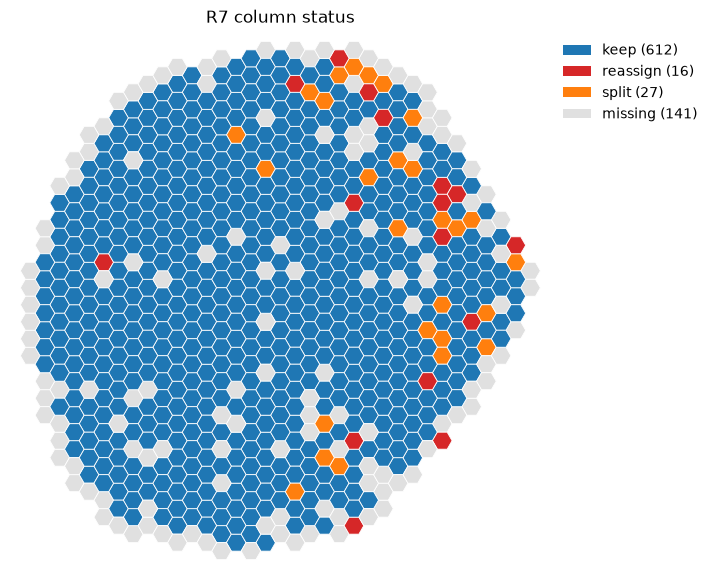

In [142]:
pr = chk.filter(pl.col("type").is_in(["R7", "R8"]))
term = (pr.filter(pl.col("depth") > -10)                                  # M4..M6 segment only
        .group_by("cell", "type", "column_id")
        .agg(pl.col("col_found").mode().first().alias("col_term"),
             (pl.col("col_found") == pl.col("col_found").mode().first()).mean().alias("frac_term"),
             pl.len().alias("n_term")))
tot = pr.group_by("cell").agg(pl.len().alias("n_all"))
term = (term.join(tot, on="cell")
        .with_columns(pl.struct(["column_id", "col_term"]).map_elements(
            lambda s: float(cnx.viz.hex_distance(pq_map[s["column_id"]], pq_map[s["col_term"]])) if s["col_term"] in pq_map else float("nan"),
            return_dtype=pl.Float64).alias("lattice_dist"))
        .with_columns(
            pl.when(pl.col("n_all") < 30).then(pl.lit("fragment"))
              .when((pl.col("col_term") == pl.col("column_id"))).then(pl.lit("keep"))
              .when((pl.col("frac_term") >= 0.7) & (pl.col("lattice_dist") == 1)).then(pl.lit("reassign"))
              .otherwise(pl.lit("split")).alias("pr_status")))
with pl.Config(tbl_rows=-1):
    print(term["pr_status"].value_counts())
    print(term.filter(pl.col("pr_status") != "keep").sort("pr_status", "frac_term"))
cnx.viz.hexmap(columns_df, dict(zip(term.filter(pl.col("type") == "R7")["column_id"], term.filter(pl.col("type") == "R7")["pr_status"])),
               colors={"keep": "tab:blue", "reassign": "tab:red", "split": "tab:orange", "fragment": "tab:purple"}, title="R7 column status");
plt.savefig('r7_reassign_map.png', bbox_inches='tight')

In [145]:
disp = (term.filter(pl.col("pr_status").is_in(["reassign", "split"]))
        .with_columns(pl.struct(["column_id", "col_term"]).map_elements(
            lambda s: f"{pq_map[s['col_term']][0] - pq_map[s['column_id']][0]:+d},{pq_map[s['col_term']][1] - pq_map[s['column_id']][1]:+d}",
            return_dtype=pl.Utf8).alias("dpq")))
print(disp.group_by("type", "dpq").len().sort("type", "len", descending=[False, True]))



shape: (9, 3)
┌──────┬───────┬─────┐
│ type ┆ dpq   ┆ len │
│ ---  ┆ ---   ┆ --- │
│ str  ┆ str   ┆ u32 │
╞══════╪═══════╪═════╡
│ R7   ┆ +0,-1 ┆ 23  │
│ R7   ┆ +1,+0 ┆ 14  │
│ R7   ┆ +0,+1 ┆ 3   │
│ R7   ┆ +1,+1 ┆ 1   │
│ R7   ┆ -1,-1 ┆ 1   │
│ R7   ┆ -1,+0 ┆ 1   │
│ R8   ┆ +1,+0 ┆ 8   │
│ R8   ┆ +0,-1 ┆ 2   │
│ R8   ┆ +0,+1 ┆ 2   │
└──────┴───────┴─────┘
